# Getting Started with `dynestyx` State Space Models

*This example reproduces the [ARMA](arma.html) and [comparing inference methods](inference_methods_comparison.html) examples with [`dynestyx`](https://github.com/BasisResearch/dynestyx) models. It is the entry point to `dynestyx` in `numpyro_forecast`. The [advanced example](dynestyx_integration.html) continues with filtering versus smoothing, the cost of a gradient, variational inference and backtesting.*

`dynestyx` is a probabilistic programming library for dynamical systems, built on NumPyro. A `DynamicalModel` holds an initial condition, a state evolution and an observation model. Effect handlers decide what `dynestyx.sample` does with it: a `Filter` or a `Smoother` integrates the latent path out and adds the marginal log likelihood to the NumPyro trace, a `LatentPathBuilder` samples the path, and a `Simulator` rolls the state forward in time.

The [`state_space`](../../reference/contrib.dynestyx.state_space.html) building block of `numpyro_forecast.contrib.dynestyx` (extra `dynestyx`) connects a `DynamicalModel` to the drivers of the package. In a model function `(covariates, data=None)`, it turns the [`Horizon`](../../reference/models.Horizon.html) into the time grids of `dynestyx.sample` and registers the `"obs"` and `"forecast"` sites that [`forecast`](../../reference/predictive.forecast.html), [`predict_in_sample`](../../reference/predictive.predict_in_sample.html) and [`to_datatree`](../../reference/convert.to_datatree.html) read. The block reads the observed series from the covariates, as [`ssoe`](../../reference/models.ssoe.html) does, because the drivers call the model without data for the in-sample predictive.

The `dynestyx` handler goes around each call that runs the model, as in the `dynestyx` examples. The same model function works under every handler, so the handler selects the inference strategy:

```python
with Filter(filter_config=KFConfig()):
    mcmc.run(rng_key, covariates_train, data_train)

with DiscreteTimeSimulator(n_simulations=1), Smoother(smoother_config=KFSmootherConfig()):
    tree = to_datatree(rng_key, model, mcmc.get_samples(), data_train, covariates)
```

We proceed as follows:

1. **ARMA(1,1).** We fit an ARMA model with `ssoe` and as a state space model with the Kalman filter, which gives the exact likelihood.
2. **Local level and Fourier regression.** We fit the BART weekly ridership model with `innovations` and with an explicit latent path from `dynestyx`, and forecast the last year with both.
3. **Integrating out the level.** With Normal noise, the Kalman filter integrates the level out, so the sampler explores only the parameters.
4. **In-sample posterior predictive.** We export the Kalman model with `to_datatree` under a Kalman smoother, without a refit.
5. **Missing data.** We fit the explicit-path model through a gap of $20$ weeks.
6. **Sampler cost.** We compare the cost of the three pairs of fits.

## Prepare Notebook

In [1]:
import numpyro

numpyro.set_host_device_count(n=4)  # before any import that initializes jax

from time import perf_counter
from typing import Literal

import arviz as az
import dynestyx as dsx
import jax
import jax.numpy as jnp
import matplotlib.pyplot as plt
import numpy as np
import numpyro.distributions as dist
import pandas as pd
import xarray as xr
from dynestyx import DiscreteTimeSimulator, DynamicalModel, Filter, LatentPathBuilder, Smoother
from dynestyx.inference.configs.smoother import KFSmootherConfig
from dynestyx.inference.filters import KFConfig
from dynestyx.models import LinearGaussianObservation, LinearGaussianStateEvolution
from jax import random
from jax.flatten_util import ravel_pytree
from jaxtyping import Float
from numpyro.infer import MCMC, NUTS
from numpyro.infer.reparam import LocScaleReparam
from numpyro.infer.util import initialize_model

from numpyro_forecast import (
    Horizon,
    eval_crps,
    forecast,
    innovations,
    predict,
    predict_in_sample,
    ssoe,
    to_datatree,
)
from numpyro_forecast.contrib.dynestyx import state_space
from numpyro_forecast.datasets import load_bart_weekly
from numpyro_forecast.features import fourier_features
from numpyro_forecast.typing import Array, ForecastModel

az.style.use("arviz-darkgrid")
plt.rcParams["figure.figsize"] = [10, 6]
plt.rcParams["figure.dpi"] = 100
plt.rcParams["figure.facecolor"] = "white"

rng_key = random.PRNGKey(seed=42)

print(f"dynestyx {dsx.__version__}, numpyro {numpyro.__version__}, jax {jax.__version__}")

%load_ext autoreload
%autoreload 2
%load_ext jaxtyping
%jaxtyping.typechecker beartype.beartype
%config InlineBackend.figure_format = "retina"

dynestyx 0.8.0, numpyro 0.22.0, jax 0.11.2


Every comparison fits both models with the same NUTS settings: $4$ chains of $1{,}000$ draws, the same warmup length and the same chain method. The helpers below run a fit, measure the cost of one gradient of the log density, and collect the diagnostics.

- `fit_nuts` returns the sampler and its wall time, which includes the compilation.
- `gradient_cost` measures the gradient of the potential energy, which NUTS evaluates at every leapfrog step. It evaluates $1{,}000$ gradients at nearby points inside one compiled loop and returns the milliseconds per gradient, without the compilation and without the Python overhead of one call per gradient.
- `convergence` reports, over the scalar parameters, the smallest bulk effective sample size (ESS), the largest $\hat{R}$ and the number of divergent transitions.
- `diagnostics` adds the wall time, the leapfrog steps per draw and the gradient evaluations of the sampling phase. The ratio of gradient evaluations to the smallest ESS measures how hard the posterior is for NUTS.

In [2]:
def fit_nuts(
    rng_key: Array,
    model: ForecastModel,
    covariates: Array,
    data: Array,
    *,
    num_warmup: int,
    chain_method: Literal["parallel", "sequential", "vectorized"],
) -> tuple[MCMC, float]:
    """Fit ``model`` with NUTS (4 chains, 1,000 draws each) and return the wall time in seconds."""
    mcmc = MCMC(
        NUTS(model),
        num_warmup=num_warmup,
        num_samples=1_000,
        num_chains=4,
        chain_method=chain_method,
        progress_bar=False,
    )
    start = perf_counter()
    mcmc.run(rng_key, covariates, data, extra_fields=("num_steps", "diverging"))
    jax.block_until_ready(mcmc.get_samples())
    return mcmc, perf_counter() - start


def gradient_cost(
    rng_key: Array, model: ForecastModel, covariates: Array, data: Array, num_evals: int = 1_000
) -> float:
    """Milliseconds per gradient of the potential energy of ``model``, in one compiled loop."""
    model_info = initialize_model(rng_key, model, model_args=(covariates, data))
    flat, unravel = ravel_pytree(model_info.param_info.z)
    # distinct points, so that the compiler cannot reuse one gradient for every iteration
    points = flat + 1e-3 * random.normal(rng_key, (num_evals, flat.size))
    value_and_grad = jax.value_and_grad(lambda z: model_info.potential_fn(unravel(z)))
    run = jax.jit(lambda z: jax.lax.map(value_and_grad, z))
    jax.block_until_ready(run(points))  # compile
    start = perf_counter()
    jax.block_until_ready(run(points))
    return (perf_counter() - start) / num_evals * 1e3


def posterior_tree(mcmc: MCMC, names: list[str]) -> xr.DataTree:
    """Return the ``(chain, draw)`` posterior of the scalar parameters ``names`` as a DataTree."""
    grouped = mcmc.get_samples(group_by_chain=True)
    return az.from_dict({"posterior": {name: np.asarray(grouped[name]) for name in names}})


def convergence(mcmc: MCMC, names: list[str]) -> dict[str, float]:
    """Smallest bulk ESS, largest R-hat and divergent transitions over the parameters ``names``."""
    summary = az.summary(posterior_tree(mcmc, names), var_names=names, round_to="none")
    return {
        "min bulk ESS": float(summary["ess_bulk"].min()),
        "max R-hat": float(summary["r_hat"].max()),
        "divergences": float(np.asarray(mcmc.get_extra_fields()["diverging"]).sum()),
    }


def diagnostics(
    mcmc: MCMC, seconds: float, ms_per_gradient: float, names: list[str]
) -> dict[str, float]:
    """Sampler cost and convergence of one fit over the scalar parameters ``names``."""
    steps = np.asarray(mcmc.get_extra_fields()["num_steps"])
    checks = convergence(mcmc, names)
    return {
        "wall time (s)": seconds,
        "leapfrog steps per draw": float(steps.mean()),
        "gradient evaluations": float(steps.sum()),
        **checks,
        "ms per gradient": ms_per_gradient,
        "gradients per effective draw": float(steps.sum()) / checks["min bulk ESS"],
    }


def cost_table(cost: dict[str, dict[str, float]]) -> pd.DataFrame:
    """One row per fit, rounded per column, with the counts as integers."""
    digits = {"wall time (s)": 1, "leapfrog steps per draw": 1, "max R-hat": 3}
    digits |= {"ms per gradient": 4, "gradients per effective draw": 1}
    counts = {"gradient evaluations": int, "min bulk ESS": int, "divergences": int}
    return pd.DataFrame(cost).T.round(digits | dict.fromkeys(counts, 0)).astype(counts)

Three plotting helpers: one overlays the posteriors of two fits, one parameter per panel, one computes the HDI bounds of forecast draws, and one writes the legend label of an HDI band.

In [3]:
def plot_posteriors(
    fits: dict[str, MCMC], names: list[str], title: str, truth: dict[str, float] | None = None
) -> None:
    """Overlay the posterior densities of ``names`` for every fit, one panel per parameter."""
    trees = {label: posterior_tree(mcmc, names) for label, mcmc in fits.items()}
    pc = az.plot_dist(
        trees,
        var_names=names,
        kind="kde",
        visuals={
            "credible_interval": False,
            "point_estimate": False,
            "point_estimate_text": False,
        },
        figure_kwargs={"figsize": (12, 3.5)},
    )
    pc.add_legend("model")
    for name in names:
        ax = pc.get_target(name, {})
        ax.set(xlabel=name, ylabel="density")
        if truth is not None:
            ax.axvline(truth[name], color="black", ls="--", lw=1)
    pc.viz["figure"].item().suptitle(title, fontsize=14, fontweight="bold")


def hdi_bounds(
    draws: Float[Array | np.ndarray, " sample time 1"], prob: float
) -> tuple[np.ndarray, np.ndarray]:
    """Lower and upper HDI bounds over the sample axis of ``(sample, time, 1)`` draws."""
    da = xr.DataArray(np.asarray(draws)[..., 0], dims=["sample", "time"])
    bounds = az.hdi(da, prob=prob, dim="sample")
    return bounds.sel(ci_bound="lower").to_numpy(), bounds.sel(ci_bound="upper").to_numpy()


def hdi_label(prob: float, prefix: str = "") -> str:
    r"""Legend label for an HDI band, e.g. ``$94\%$ HDI``."""
    percent = f"{prob:.0%}".replace("%", r"\%")
    return f"{prefix}${percent}$ HDI"

## ARMA(1,1)

The [ARMA example](arma.html) writes the ARMA(1,1) model

$$
y_t = \mu + \phi \, y_{t-1} + \theta \, \varepsilon_{t-1} + \varepsilon_t, \qquad \varepsilon_t \sim \text{Normal}(0, \sigma)
$$

with `ssoe`, which conditions on $y_{-1} = \mu$ and $\varepsilon_{-1} = 0$. The same model is a linear-Gaussian state space model, so the Kalman filter gives the exact likelihood instead. With the deviation $a_t = y_t - c$ from the process mean $c = \mu / (1 - \phi)$, the state $x_t = (a_t, \theta \varepsilon_t)$ follows

$$
x_t = A x_{t-1} + g \, \varepsilon_t, \qquad A = \begin{pmatrix} \phi & 1 \\ 0 & 0 \end{pmatrix}, \qquad g = \begin{pmatrix} 1 \\ \theta \end{pmatrix},
$$

so the state covariance is $Q = \sigma^2 g g^\top$, and the observation is $y_t = H x_t + c$ with $H = (1, 0)$. The initial state has the stationary covariance $P_0$, the solution of $P_0 = A P_0 A^\top + Q$. The state noise has rank one, so we add a small jitter $\delta = 10^{-4} \sigma^2$ to $Q$, to $P_0$ and as the observation variance, which keeps the Cholesky factors defined in single precision.

We simulate $100$ steps with $\phi = 0.4$, $\theta = 0.7$ and $\sigma = 0.5$. The priors are those of the ARMA example, which also checks them with prior predictive samples.

In [4]:
phi_true, theta_true, noise_scale, n_steps = 0.4, 0.7, 0.5, 100


def simulate_arma(
    rng_key: Array, n: int, phi: float, theta: float, scale: float
) -> Float[Array, " time"]:
    """Simulate ``n`` steps of a zero-mean ARMA(1,1) process."""
    error = scale * random.normal(rng_key, (n + 1,))

    def step(carry: tuple[Array, Array], noise: Array) -> tuple[tuple[Array, Array], Array]:
        y_prev, error_prev = carry
        y_t = phi * y_prev + theta * error_prev + noise
        return (y_t, noise), y_t

    return jax.lax.scan(step, (jnp.zeros(()), error[0]), error[1:])[1]


rng_key, rng_subkey = random.split(rng_key)
arma_data = simulate_arma(rng_subkey, n_steps, phi_true, theta_true, noise_scale)[:, None]
arma_covariates = arma_data  # both models read the observed series from the covariates

The `numpyro_forecast` model, as in the ARMA example:

In [5]:
def arma_ssoe(covariates: Array, data: Array | None = None) -> None:
    """ARMA(1,1) in innovations form with ``ssoe``."""
    h = Horizon.from_data(covariates, data)
    y = covariates[..., : h.t_obs, :]
    mu = numpyro.sample("mu", dist.Normal(loc=0, scale=1))
    phi = numpyro.sample("phi", dist.Uniform(low=-1, high=1))
    theta = numpyro.sample("theta", dist.Uniform(low=-1, high=1))
    sigma = numpyro.sample("sigma", dist.HalfNormal(scale=1))

    def mean(carry: tuple[Array, Array], _: Array | None) -> Array:
        y_prev, error_prev = carry
        return mu + phi * y_prev + theta * error_prev

    def update(
        carry: tuple[Array, Array], y_t: Array, eps_t: Array, _: Array | None
    ) -> tuple[Array, Array]:
        return y_t, eps_t

    result = ssoe(h, "eps", y, (mu[None], jnp.zeros((1,))), mean, update, dist.Normal(0, sigma))
    numpyro.sample("obs", dist.Normal(loc=result.mu, scale=sigma), obs=h.data)
    if h.future > 0:
        numpyro.deterministic("forecast", result.y_future)

The `dynestyx` model has the same priors. `arma_dynamics` builds the matrices above, and the model function reads the series from the covariates and hands the `Horizon`, the window and the dynamics to `state_space`.

In [6]:
def arma_dynamics(mu: Array, phi: Array, theta: Array, sigma: Array) -> DynamicalModel:
    """ARMA(1,1) as a linear-Gaussian state space model with a stationary initial state."""
    A = jnp.array([[phi, 1.0], [0.0, 0.0]])
    g = jnp.array([1.0, theta])
    Q = sigma**2 * jnp.outer(g, g)
    jitter = 1e-4 * sigma**2 * jnp.eye(2)
    P0 = jnp.linalg.solve(jnp.eye(4) - jnp.kron(A, A), Q.reshape(-1)).reshape(2, 2)
    return DynamicalModel(
        initial_condition=dist.MultivariateNormal(jnp.zeros(2), 0.5 * (P0 + P0.T) + jitter),
        state_evolution=LinearGaussianStateEvolution(A=A, cov=Q + jitter),
        observation_model=LinearGaussianObservation(
            H=jnp.array([[1.0, 0.0]]), R=jitter[:1, :1], bias=(mu / (1.0 - phi))[None]
        ),
    )


def arma_ssm(covariates: Array, data: Array | None = None) -> None:
    """ARMA(1,1) as a dynestyx state space model."""
    h = Horizon.from_data(covariates, data)
    y = covariates[..., : h.t_obs, :]  # the observed window travels in the covariates
    mu = numpyro.sample("mu", dist.Normal(loc=0, scale=1))
    phi = numpyro.sample("phi", dist.Uniform(low=-1, high=1))
    theta = numpyro.sample("theta", dist.Uniform(low=-1, high=1))
    sigma = numpyro.sample("sigma", dist.HalfNormal(scale=1))
    state_space(h, "f", y, arma_dynamics(mu, phi, theta, sigma))

We fit both models with parallel chains. The `dynestyx` fit runs under a Kalman filter on the `cd_dynamax` backend. We pass `KFConfig` explicitly: without a configuration, `Filter()` uses an ensemble Kalman filter, which is approximate.

In [7]:
arma_names = ["mu", "phi", "theta", "sigma"]
kalman = Filter(filter_config=KFConfig(filter_source="cd_dynamax"))
rng_key, key_ssoe, key_kalman, key_grad = random.split(rng_key, 4)

mcmc_arma_ssoe, seconds = fit_nuts(
    key_ssoe, arma_ssoe, arma_covariates, arma_data, num_warmup=1_000, chain_method="parallel"
)
ms = gradient_cost(key_grad, arma_ssoe, arma_covariates, arma_data)
arma_cost = {"ssoe": diagnostics(mcmc_arma_ssoe, seconds, ms, arma_names)}

with kalman:
    mcmc_arma_kalman, seconds = fit_nuts(
        key_kalman, arma_ssm, arma_covariates, arma_data, num_warmup=1_000, chain_method="parallel"
    )
    ms = gradient_cost(key_grad, arma_ssm, arma_covariates, arma_data)

arma_cost["dynestyx Kalman filter"] = diagnostics(mcmc_arma_kalman, seconds, ms, arma_names)

cost_table(arma_cost)

,wall time (s),leapfrog steps per draw,gradient evaluations,min bulk ESS,max R-hat,divergences,ms per gradient,gradients per effective draw
ssoe,1.5,7.8,31264,2206,1.002,0,0.0055,14.2
dynestyx Kalman filter,18.9,7.5,29844,1866,1.002,0,0.7659,16.0


Both fits converge: the largest $\hat{R}$ is $1.002$, the smallest bulk ESS is above $1{,}800$ of the $4{,}000$ draws, and there are no divergent transitions. Neither model samples a path, so NUTS takes about the same number of leapfrog steps per draw ($7.8$ and $7.5$). A gradient of the Kalman filter costs about $140$ times more ($0.7659$ against $0.0055$ milliseconds), because every step propagates and updates a $2 \times 2$ state covariance, where the `ssoe` recursion is one multiply-add. The wall time ($1.5$ against $18.9$ seconds) also includes the warmup and the compilation.

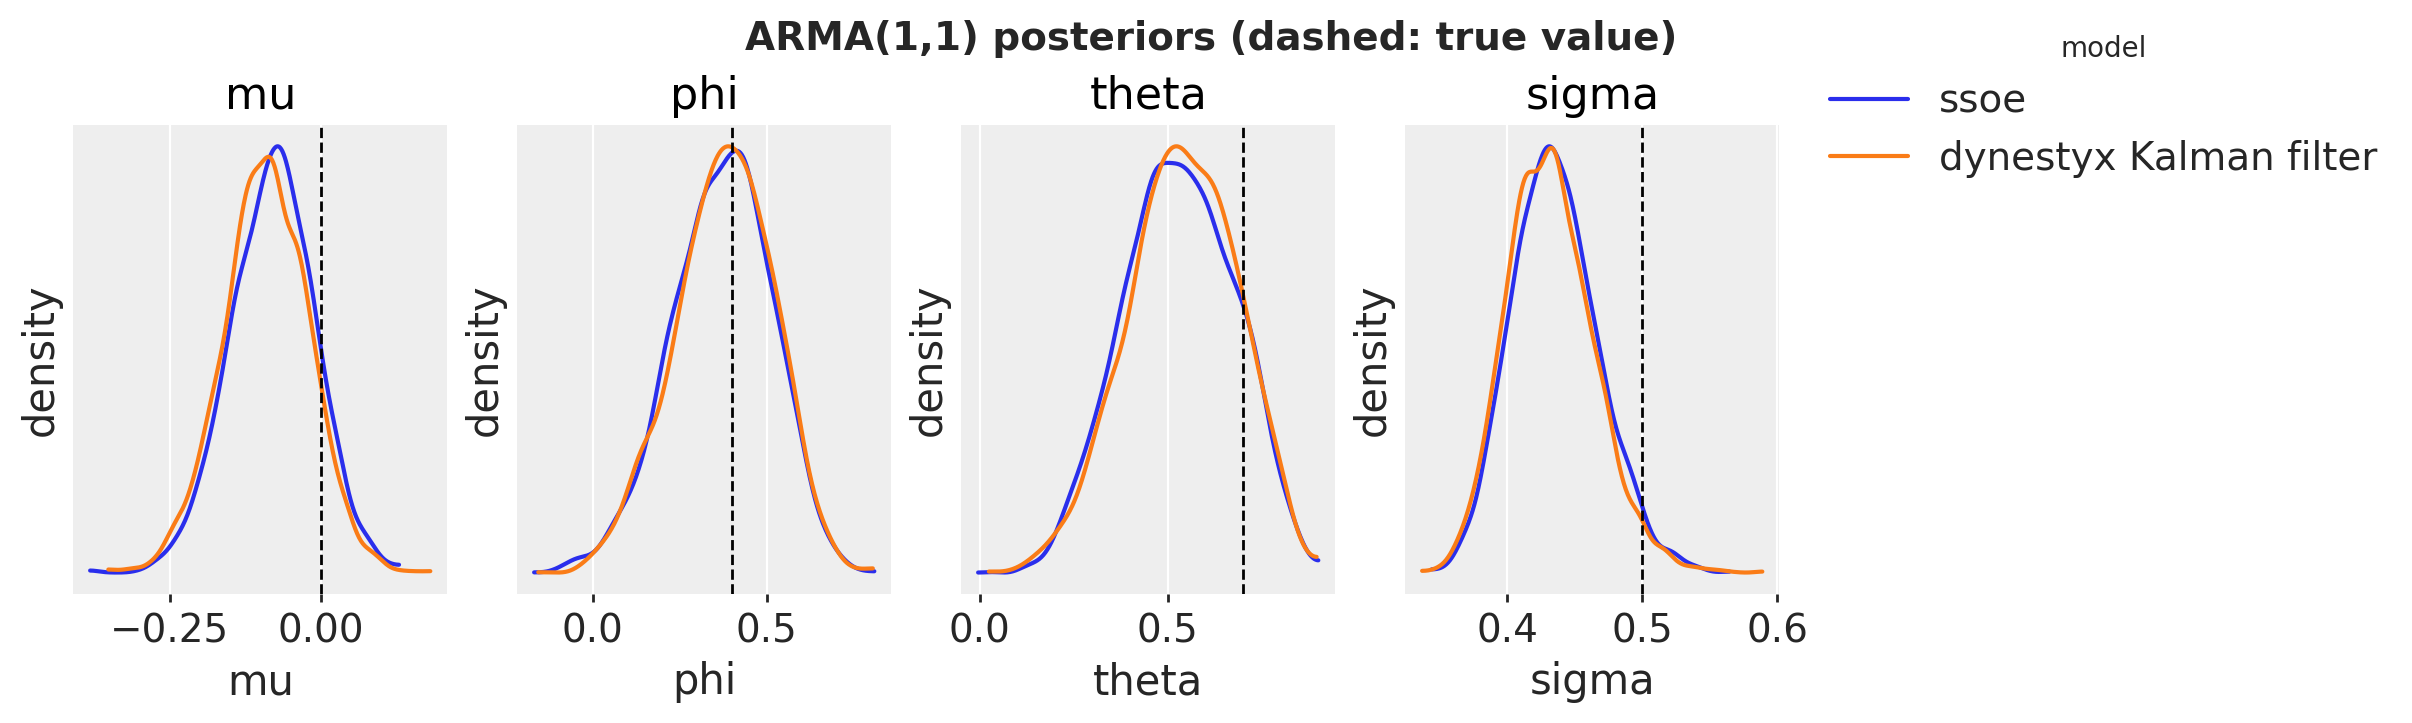

In [8]:
plot_posteriors(
    {"ssoe": mcmc_arma_ssoe, "dynestyx Kalman filter": mcmc_arma_kalman},
    arma_names,
    title="ARMA(1,1) posteriors (dashed: true value)",
    truth={"mu": 0.0, "phi": phi_true, "theta": theta_true, "sigma": noise_scale},
)

The two posteriors agree. The true values of $\mu$, $\phi$ and $\theta$ lie inside the bulk of both, and the true $\sigma = 0.5$ lies in the upper tail of both, so that difference comes from the simulated data, not from the method. The `ssoe` likelihood conditions on the first observation and the Kalman filter likelihood is exact, but with $100$ observations the difference does not show.

## Local Level and Fourier Regression

The [comparing inference methods](inference_methods_comparison.html) example fits a random walk level plus a Fourier regression with Student-T noise to the weekly BART ridership:

$$
\begin{align*}
\ell_t &= \ell_{t-1} + w_t, \qquad w_t \sim \text{Normal}(0, s), \\
y_t &= b + \ell_t + \beta^\top u_t + v_t, \qquad v_t \sim \text{StudentT}(\nu, 0, \sigma),
\end{align*}
$$

where $y_t$ is the log ridership of week $t$, $u_t$ holds the $52$ Fourier terms of the yearly cycle, and $s$ is the `drift_scale`. The priors are those of the comparing inference methods example. We hold out the last $52$ weeks.

The covariate array carries the series in column $0$ and the Fourier terms in columns `1:`. The `dynestyx` model reads its observed window from column $0$, and the `numpyro_forecast` model ignores it.

In [9]:
bart = load_bart_weekly()
duration = bart.shape[0]
t_obs = duration - 52
bart_train, bart_test = bart[:t_obs], bart[t_obs:]
week = np.arange(duration)

fourier = fourier_features(duration, period=365.25 / 7, num_terms=26)
bart_covariates = jnp.concatenate([bart, fourier], axis=-1)  # (duration, 53)

print(f"covariates {bart_covariates.shape}, train {bart_train.shape}, test {bart_test.shape}")

covariates (469, 53), train (417, 1), test (52, 1)


The `numpyro_forecast` model samples the $417$ weekly steps of the level with [`innovations`](../../reference/models.innovations.html). The comparing inference methods example also samples a `centered` site for its `LocScaleReparam`. That site only selects a parameterization, so its posterior equals its prior and NUTS mixes poorly on it. Here we fix the non-centered form instead.

In [10]:
def univariate_model(covariates: Array, data: Array | None = None) -> None:
    """Random walk level plus Fourier regression with Student-T noise, with ``innovations``."""
    h = Horizon.from_data(covariates, data)
    fourier = covariates[..., 1:]  # column 0 is the series, read only by the dynestyx model
    bias = numpyro.sample("bias", dist.Normal(0.0, 10.0))
    weight = numpyro.sample(
        "weight", dist.Normal(0.0, 0.1).expand([fourier.shape[-1]]).to_event(1)
    )
    drift_scale = numpyro.sample("drift_scale", dist.LogNormal(-20.0, 5.0))
    nu = numpyro.sample("nu", dist.Gamma(10.0, 2.0))
    sigma = numpyro.sample("sigma", dist.LogNormal(-5.0, 5.0))
    drift = innovations(
        h, "drift", dist.Normal(0.0, drift_scale), reparam=LocScaleReparam(centered=0)
    )
    level = jnp.cumsum(drift, axis=-2)
    regression = (weight * fourier).sum(axis=-1, keepdims=True)
    predict(h, dist.StudentT(df=nu, loc=0.0, scale=sigma), level + bias + regression)

Student-T noise rules out an exact Kalman filter. A particle filter does not combine well with NUTS here: with resampling, the likelihood estimate is not continuous in the parameters, and without it the weights collapse over $417$ weeks. The `dynestyx` model therefore samples the level with a `LatentPathBuilder`, as `innovations` does. The observation model is a function of the state $x_t$, the controls $u_t$ and the time $t$, and the Fourier terms enter as controls over the whole horizon, so the forecast reads their future rows from the covariates.

The builder samples the states $x_t = b + \ell_t$ directly (the centered form), not their steps. With the intercept $b$ as a separate parameter, a change of $b$ must move all $417$ states the other way. In this form the intercept is the initial state, so the `dynestyx` model has no `bias` site and gives the initial state the $\text{Normal}(0, 10)$ prior of the intercept. The two models differ only in the variance $s^2$ that the first step adds to this prior, which is negligible.

In [11]:
def level_regression(covariates: Array, data: Array | None = None) -> None:
    """Random walk level plus Fourier regression with Student-T noise, as a dynestyx model."""
    h = Horizon.from_data(covariates, data)
    y = covariates[..., : h.t_obs, :1]  # the observed window, (t_obs, 1)
    controls = covariates[..., 1:]  # the Fourier terms over the whole horizon, (duration, 52)
    weight = numpyro.sample(
        "weight", dist.Normal(0.0, 0.1).expand([controls.shape[-1]]).to_event(1)
    )
    drift_scale = numpyro.sample("drift_scale", dist.LogNormal(-20.0, 5.0))
    nu = numpyro.sample("nu", dist.Gamma(10.0, 2.0))
    sigma = numpyro.sample("sigma", dist.LogNormal(-5.0, 5.0))

    def observation(x: Array, u: Array | None, t: Array) -> dist.Distribution:
        regression = 0.0 if u is None else u @ weight
        return dist.StudentT(nu, x + regression, sigma).to_event(1)

    dynamics = DynamicalModel(
        initial_condition=dist.Normal(0.0, 10.0).expand([1]).to_event(1),  # the intercept
        state_evolution=lambda x, u, t_now, t_next: dist.Normal(x, drift_scale).to_event(1),
        observation_model=observation,
        control_dim=controls.shape[-1],
    )
    state_space(h, "f", y, dynamics, controls=controls)

Both fits run their chains one after the other (`chain_method="sequential"`). Parallel chains under a `LatentPathBuilder` crashed the Python process with `dynestyx` $0.8.0$ on the machine that executed this notebook, and a fair wall time needs the same chain method on both sides.

We keep the `LatentPathBuilder` instance of the fit. The builder records the pattern of missing observations from the concrete data of the fit, and the drivers later run the model under `jax.jit`, where the data are traced, so every later call must use the same instance.

In [12]:
bart_names = ["drift_scale", "nu", "sigma"]  # the parameters both models share
latent_path = LatentPathBuilder()
rng_key, key_innovations, key_latent, key_grad = random.split(rng_key, 4)

mcmc_innovations, seconds = fit_nuts(
    key_innovations,
    univariate_model,
    bart_covariates[:t_obs],
    bart_train,
    num_warmup=2_000,
    chain_method="sequential",
)
ms = gradient_cost(key_grad, univariate_model, bart_covariates[:t_obs], bart_train)
bart_cost = {"innovations": diagnostics(mcmc_innovations, seconds, ms, bart_names)}

with latent_path:
    mcmc_latent, seconds = fit_nuts(
        key_latent,
        level_regression,
        bart_covariates[:t_obs],
        bart_train,
        num_warmup=2_000,
        chain_method="sequential",
    )
    ms = gradient_cost(key_grad, level_regression, bart_covariates[:t_obs], bart_train)

bart_cost["dynestyx latent path"] = diagnostics(mcmc_latent, seconds, ms, bart_names)

cost_table(bart_cost)

,wall time (s),leapfrog steps per draw,gradient evaluations,min bulk ESS,max R-hat,divergences,ms per gradient,gradients per effective draw
innovations,111.7,255.0,1020000,1206,1.002,0,0.0191,845.8
dynestyx latent path,20.6,107.0,427904,117,1.057,0,0.0161,3646.5


The explicit path takes fewer leapfrog steps per draw than `innovations` ($107$ against $255$), its gradients are slightly cheaper ($0.0161$ against $0.0191$ milliseconds), and it needs less than a fifth of the wall time ($20.6$ against $111.7$ seconds). But it does not converge as well. Its largest $\hat{R}$ is $1.057$, above the usual threshold of $1.01$, and its smallest bulk ESS is $117$, so per effective draw it needs about four times as many gradients ($3{,}646$ against $846$). Neither fit has divergent transitions. The diagnostics per parameter show which parameter is slow:

In [13]:
pd.concat(
    {
        label: az.summary(posterior_tree(mcmc, bart_names), var_names=bart_names, round_to="none")
        for label, mcmc in (
            ("innovations", mcmc_innovations),
            ("dynestyx latent path", mcmc_latent),
        )
    },
    names=["fit", "parameter"],
)[["mean", "sd", "ess_bulk", "r_hat"]].round({"mean": 4, "sd": 4, "ess_bulk": 0, "r_hat": 3})

mean      sd  ess_bulk  r_hat
fit                  parameter                                   
innovations          drift_scale  0.0044  0.0007    1372.0  1.000
                     nu           1.5781  0.2211    1873.0  1.001
                     sigma        0.0173  0.0020    1206.0  1.002
dynestyx latent path drift_scale  0.0047  0.0008     117.0  1.057
                     nu           1.5632  0.2231    2633.0  1.002
                     sigma        0.0171  0.0020    1954.0  1.003

`drift_scale`, the scale of the weekly steps of the level, is the slow parameter of the explicit path: its bulk ESS is $117$, against $1{,}372$ under `innovations`, while `nu` and `sigma` mix well under both. The builder samples the states in centered form and has no reparameterization option, while `innovations` samples the non-centered steps, so the leapfrog counts compare two parameterizations as well as two libraries. The summaries of the explicit path are approximate, and longer chains would make them more reliable.

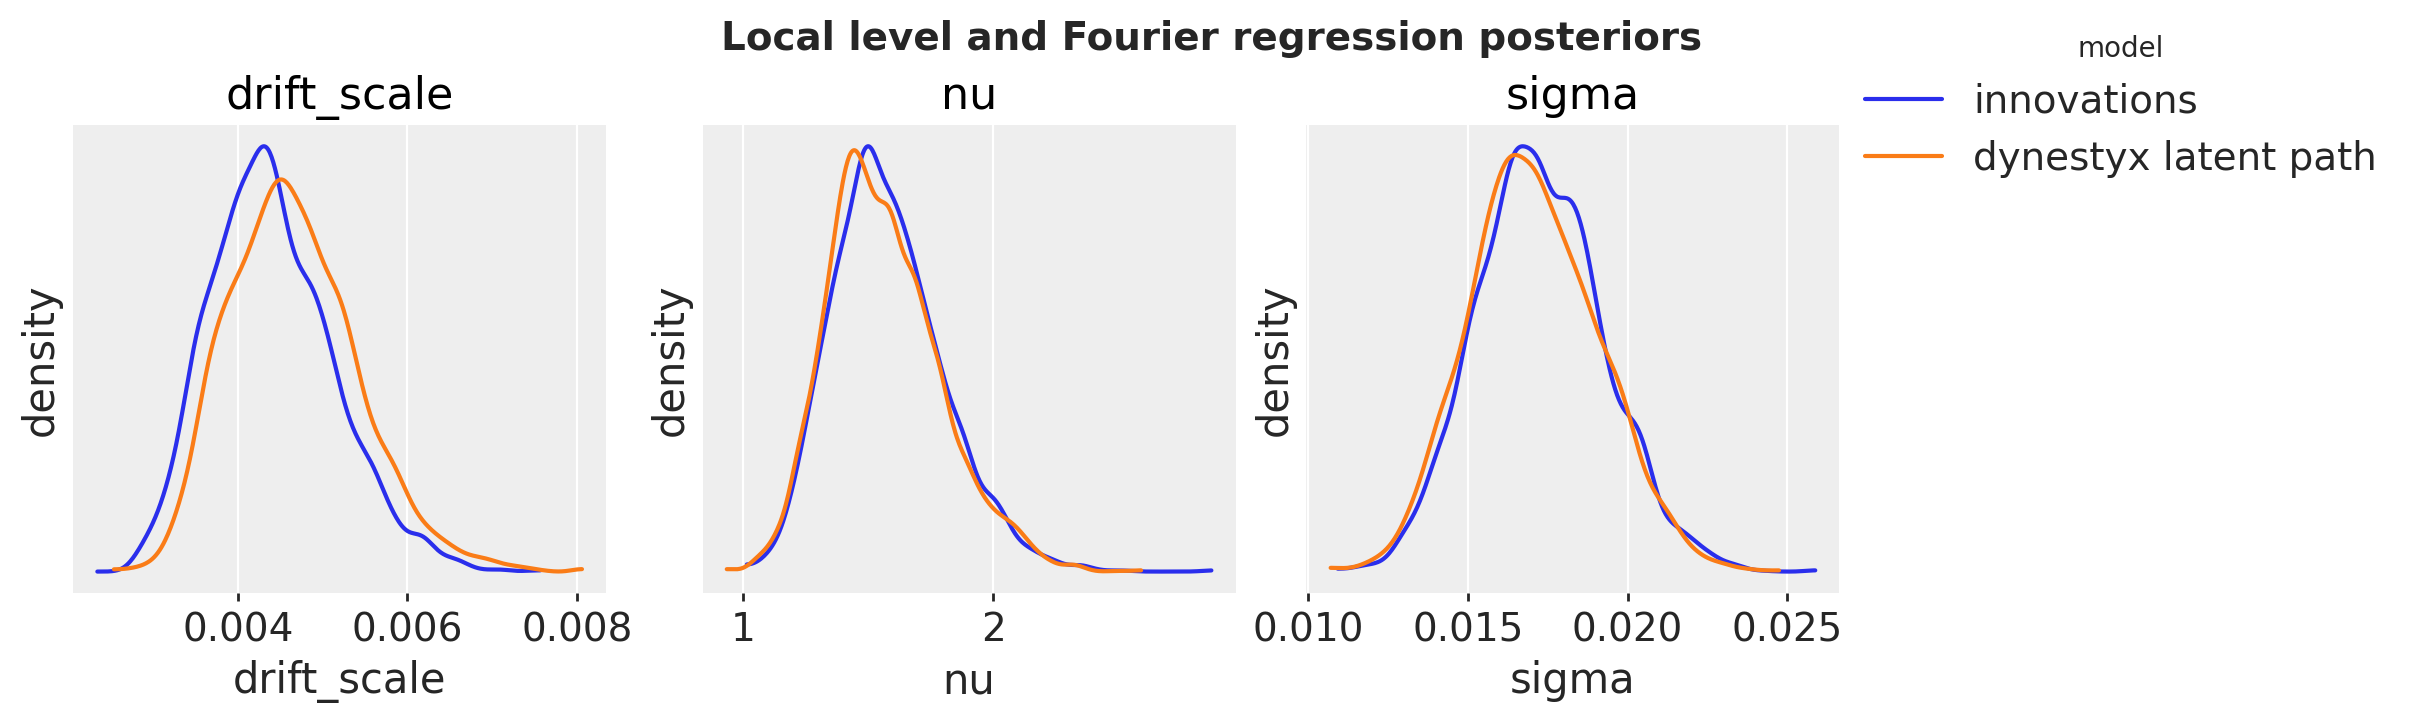

In [14]:
plot_posteriors(
    {"innovations": mcmc_innovations, "dynestyx latent path": mcmc_latent},
    bart_names,
    title="Local level and Fourier regression posteriors",
)

The densities of `nu` and `sigma` coincide. The `drift_scale` density of the explicit path sits a little to the right (posterior mean $0.0047$ against $0.0044$). That fit has not converged on `drift_scale`, so the shift may come from its slow mixing.

Both models forecast through `forecast`. For the `dynestyx` model, the block reads the forecast from the rollout of a `DiscreteTimeSimulator` around the call. `dynestyx` places the initial state of the rollout at the first prediction time, so the block asks for one extra step at the last observation and drops it: the first forecast week is a transition of the final level, not a copy of it. The `LatentPathBuilder` around the call is the instance that fitted the model.

In [15]:
rng_key, key_innovations, key_latent = random.split(rng_key, 3)
bart_forecasts = {
    "innovations": forecast(
        key_innovations,
        univariate_model,
        mcmc_innovations.get_samples(),
        bart_train,
        bart_covariates,
        batch_size=500,
    )
}

with DiscreteTimeSimulator(n_simulations=1), latent_path:
    bart_forecasts["dynestyx latent path"] = forecast(
        key_latent,
        level_regression,
        mcmc_latent.get_samples(),
        bart_train,
        bart_covariates,
        batch_size=500,
    )

pd.Series(
    {label: float(eval_crps(draws, bart_test)) for label, draws in bart_forecasts.items()},
    name="test CRPS",
).round(4)

innovations             0.0301
dynestyx latent path    0.0303
Name: test CRPS, dtype: float64

We plot the `dynestyx` forecast with its $50\%$ and $94\%$ HDI bands, and the `innovations` forecast as its median and the bounds of its $50\%$ and $94\%$ HDI bands. We show medians, not means: with $\nu$ close to $1.5$ the Student-T noise has no finite variance, so the mean of the draws moves with a few extreme draws.

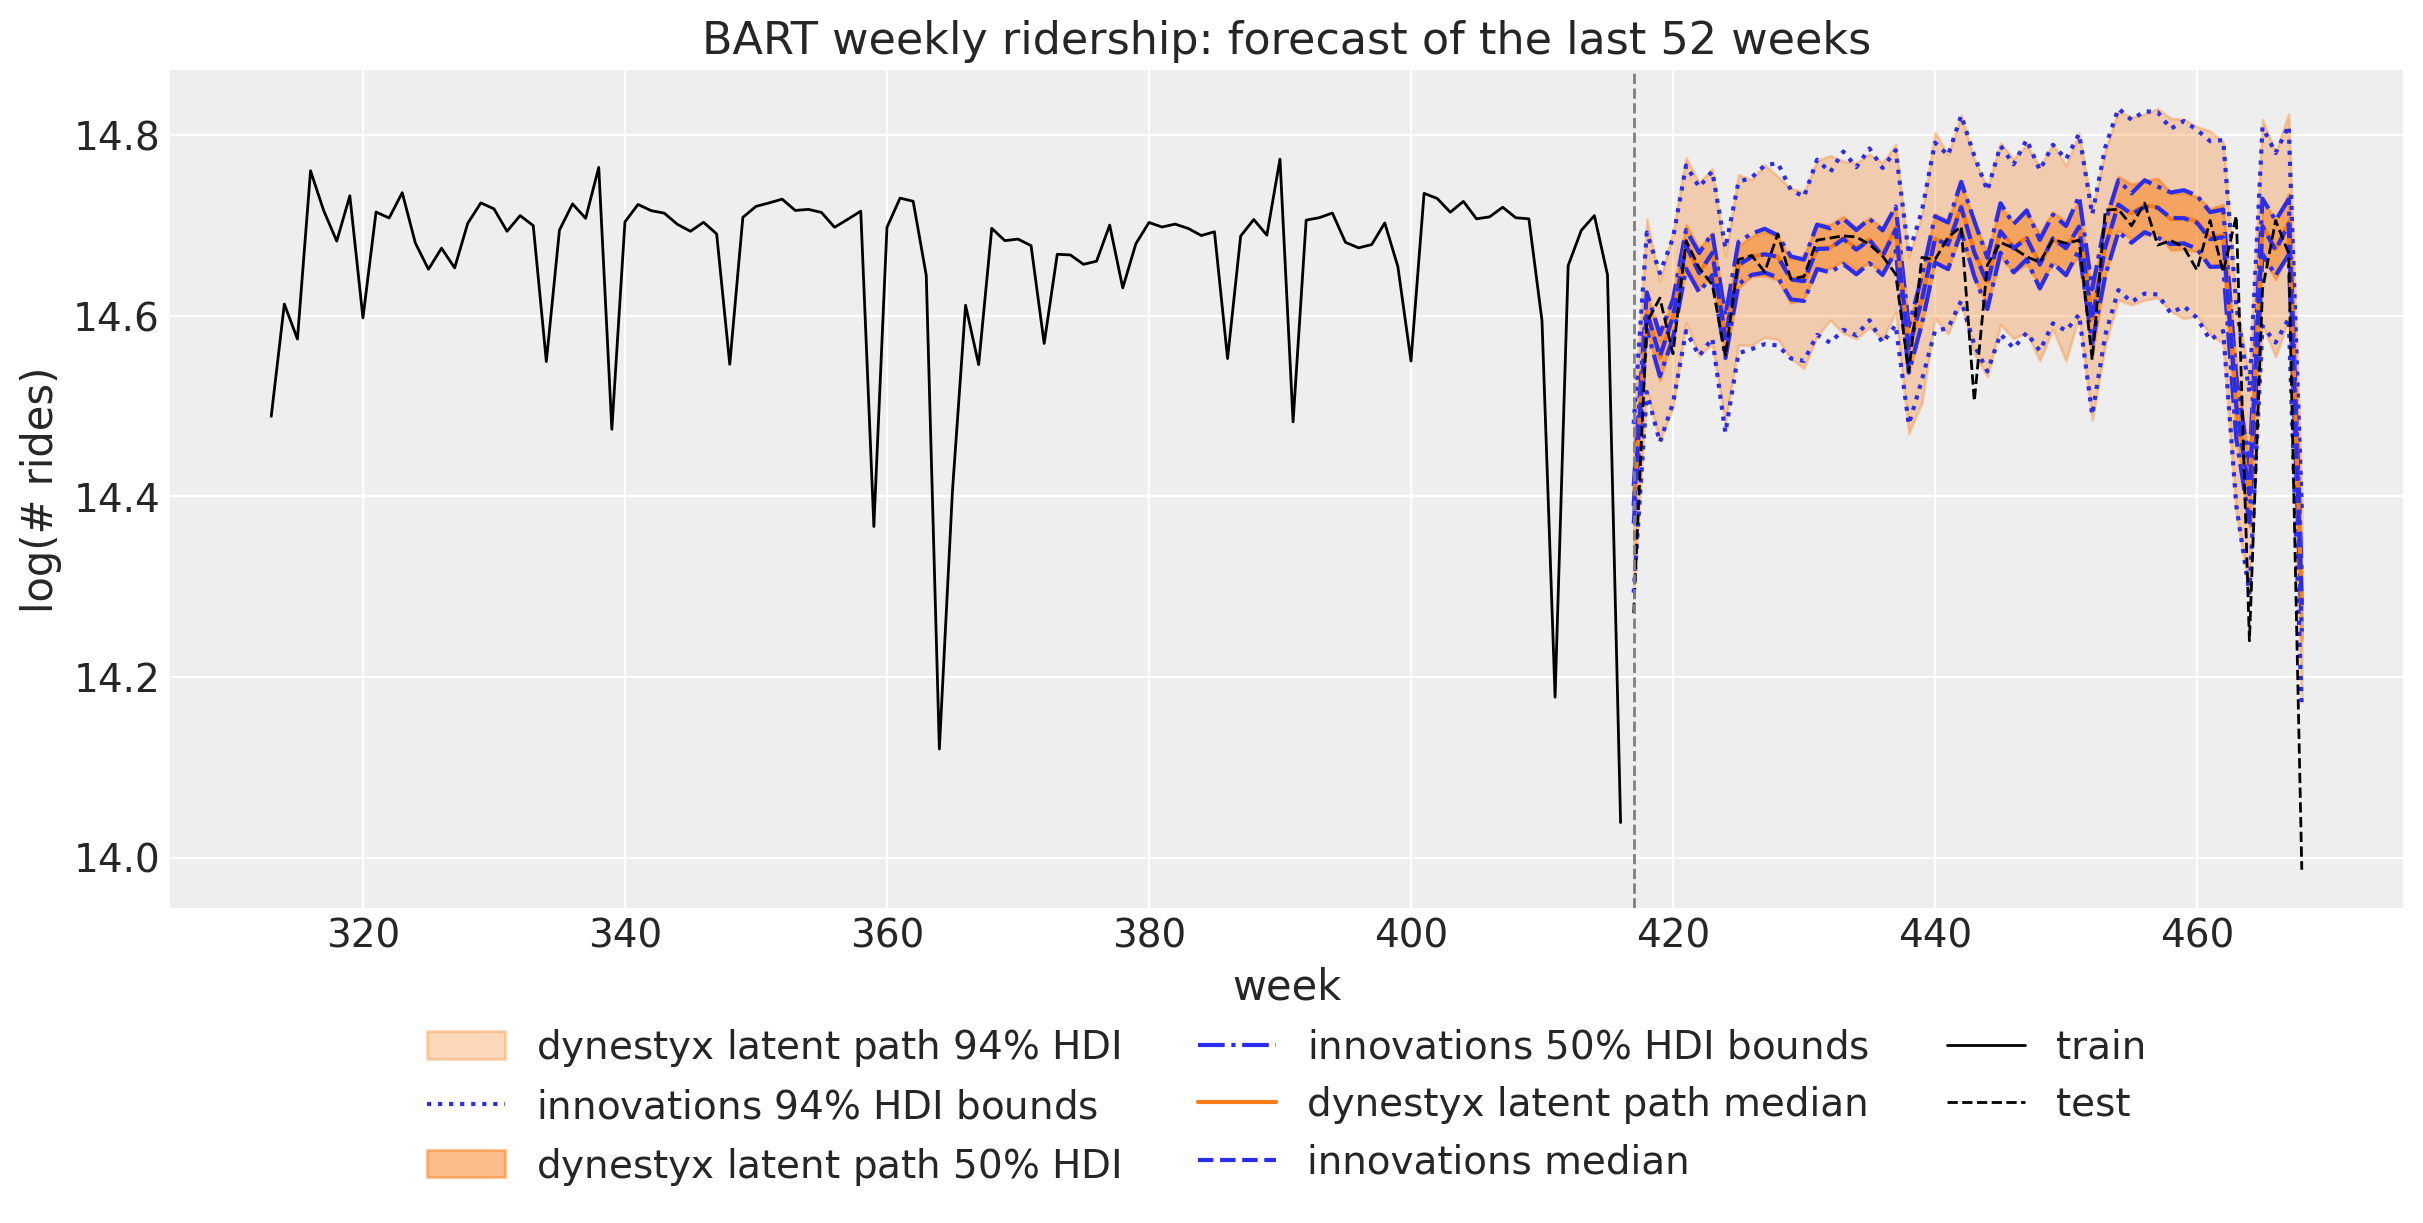

In [16]:
fig, ax = plt.subplots(figsize=(12, 6))
history = slice(t_obs - 104, t_obs)
draws_latent = bart_forecasts["dynestyx latent path"]
draws_innovations = bart_forecasts["innovations"]

for prob, alpha, ls in ((0.94, 0.3, ":"), (0.5, 0.5, "-.")):
    lower, upper = hdi_bounds(draws_latent, prob)
    ax.fill_between(
        week[t_obs:],
        lower,
        upper,
        color="C1",
        alpha=alpha,
        label=hdi_label(prob, prefix="dynestyx latent path "),
    )
    lower, upper = hdi_bounds(draws_innovations, prob)
    ax.plot(
        week[t_obs:], lower, color="C0", ls=ls, label=hdi_label(prob, "innovations ") + " bounds"
    )
    ax.plot(week[t_obs:], upper, color="C0", ls=ls)

ax.plot(
    week[t_obs:],
    np.median(np.asarray(draws_latent), axis=0)[:, 0],
    color="C1",
    label="dynestyx latent path median",
)
ax.plot(
    week[t_obs:],
    np.median(np.asarray(draws_innovations), axis=0)[:, 0],
    color="C0",
    ls="--",
    label="innovations median",
)
ax.plot(week[history], bart_train[history, 0], color="black", lw=1, label="train")
ax.plot(week[t_obs:], bart_test[:, 0], color="black", lw=1, ls="--", label="test")
ax.axvline(t_obs, color="gray", ls="--", lw=1)
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncols=3)
ax.set(
    title="BART weekly ridership: forecast of the last 52 weeks",
    xlabel="week",
    ylabel="log(# rides)",
);

The two forecasts agree. The test CRPS is $0.0301$ for `innovations` and $0.0303$ for the explicit path, and the medians and the $94\%$ HDI bounds of the two models lie on top of each other over the whole test year. The slow mixing of `drift_scale` does not show in the forecast.

## Integrating Out the Level

With Normal noise the same model is linear and Gaussian. The Kalman filter then integrates the level out exactly, and NUTS explores the $55$ parameters only, not the $417$ weekly steps of the level as well. In `dynestyx` terms, the regression is the control matrix `D` of the observation model and the bias is its offset.

In [17]:
def gaussian_model(covariates: Array, data: Array | None = None) -> None:
    """Random walk level plus Fourier regression with Normal noise, with ``innovations``."""
    h = Horizon.from_data(covariates, data)
    fourier = covariates[..., 1:]
    bias = numpyro.sample("bias", dist.Normal(0.0, 10.0))
    weight = numpyro.sample(
        "weight", dist.Normal(0.0, 0.1).expand([fourier.shape[-1]]).to_event(1)
    )
    drift_scale = numpyro.sample("drift_scale", dist.LogNormal(-20.0, 5.0))
    sigma = numpyro.sample("sigma", dist.LogNormal(-5.0, 5.0))
    drift = innovations(
        h, "drift", dist.Normal(0.0, drift_scale), reparam=LocScaleReparam(centered=0)
    )
    level = jnp.cumsum(drift, axis=-2)
    regression = (weight * fourier).sum(axis=-1, keepdims=True)
    predict(h, dist.Normal(0.0, sigma), level + bias + regression)


def gaussian_ssm(covariates: Array, data: Array | None = None) -> None:
    """Random walk level plus Fourier regression with Normal noise, as a dynestyx model."""
    h = Horizon.from_data(covariates, data)
    y = covariates[..., : h.t_obs, :1]
    controls = covariates[..., 1:]
    bias = numpyro.sample("bias", dist.Normal(0.0, 10.0))
    weight = numpyro.sample(
        "weight", dist.Normal(0.0, 0.1).expand([controls.shape[-1]]).to_event(1)
    )
    drift_scale = numpyro.sample("drift_scale", dist.LogNormal(-20.0, 5.0))
    sigma = numpyro.sample("sigma", dist.LogNormal(-5.0, 5.0))
    dynamics = DynamicalModel(
        initial_condition=dist.MultivariateNormal(jnp.zeros(1), drift_scale**2 * jnp.eye(1)),
        state_evolution=LinearGaussianStateEvolution(
            A=jnp.eye(1), cov=drift_scale**2 * jnp.eye(1)
        ),
        observation_model=LinearGaussianObservation(
            H=jnp.eye(1), R=sigma**2 * jnp.eye(1), D=weight[None, :], bias=bias[None]
        ),
        control_dim=controls.shape[-1],
    )
    state_space(h, "f", y, dynamics, controls=controls)

Both fits run parallel chains, which the Kalman filter supports. This model keeps the `bias` site of the `innovations` model: the filter integrates the states out, so no sampled path couples the intercept to the states.

In [18]:
gaussian_names = ["bias", "drift_scale", "sigma"]
rng_key, key_gaussian, key_gaussian_kalman, key_grad = random.split(rng_key, 4)

mcmc_gaussian, seconds = fit_nuts(
    key_gaussian,
    gaussian_model,
    bart_covariates[:t_obs],
    bart_train,
    num_warmup=2_000,
    chain_method="parallel",
)
ms = gradient_cost(key_grad, gaussian_model, bart_covariates[:t_obs], bart_train)
gaussian_cost = {"innovations": diagnostics(mcmc_gaussian, seconds, ms, gaussian_names)}

with kalman:
    mcmc_gaussian_kalman, seconds = fit_nuts(
        key_gaussian_kalman,
        gaussian_ssm,
        bart_covariates[:t_obs],
        bart_train,
        num_warmup=2_000,
        chain_method="parallel",
    )
    ms = gradient_cost(key_grad, gaussian_ssm, bart_covariates[:t_obs], bart_train)

gaussian_cost["dynestyx Kalman filter"] = diagnostics(
    mcmc_gaussian_kalman, seconds, ms, gaussian_names
)

cost_table(gaussian_cost)

,wall time (s),leapfrog steps per draw,gradient evaluations,min bulk ESS,max R-hat,divergences,ms per gradient,gradients per effective draw
innovations,26.6,114.5,458105,1599,1.001,11,0.0163,286.4
dynestyx Kalman filter,101.2,7.8,31272,4234,1.002,0,1.3012,7.4


The largest $\hat{R}$ is $1.002$ and the smallest bulk ESS is $1{,}599$. The `innovations` fit reports $11$ divergent transitions in $4{,}000$ draws, a sign that it does not explore every region of the posterior; the Kalman filter reports none. The Kalman filter needs $7.8$ leapfrog steps per draw against $114.5$, and about $40$ times fewer gradients per effective draw ($7.4$ against $286.4$). Each of its gradients runs the filter over the $417$ weeks and costs about $80$ times more ($1.3012$ against $0.0163$ milliseconds). The Sampler Cost section compares the two effects. The wall time, which includes the warmup and the compilation, is longer for the filter ($101.2$ against $26.6$ seconds).

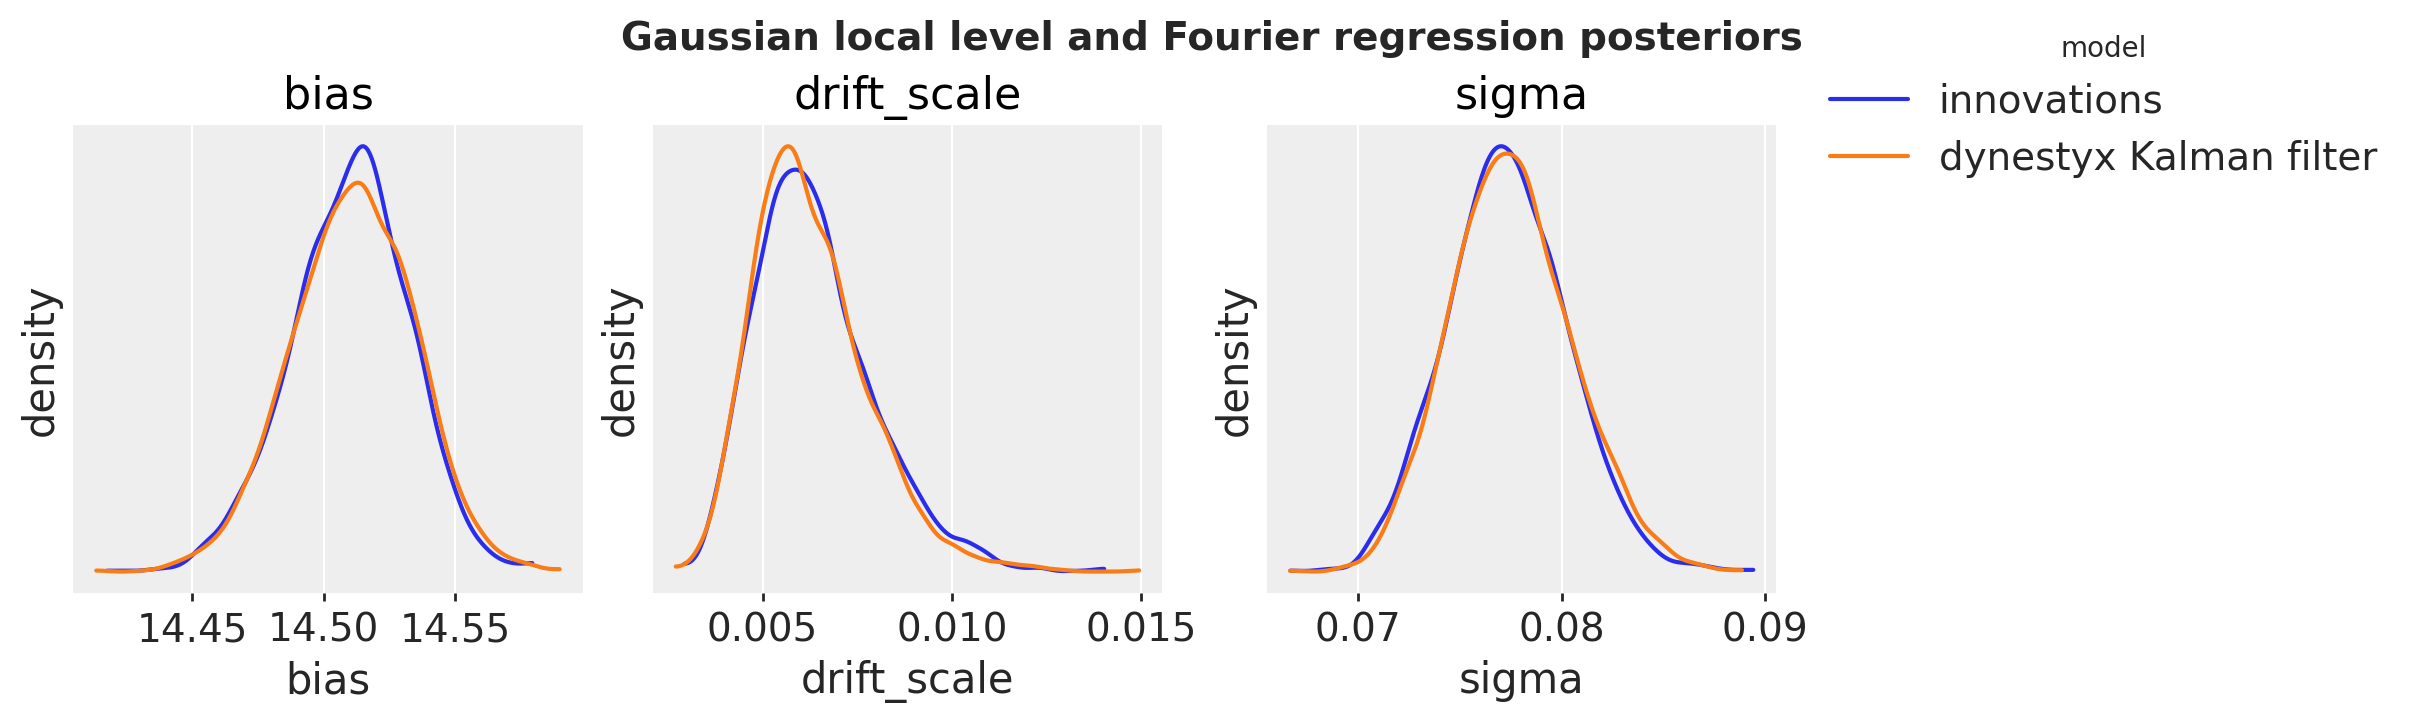

In [19]:
plot_posteriors(
    {"innovations": mcmc_gaussian, "dynestyx Kalman filter": mcmc_gaussian_kalman},
    gaussian_names,
    title="Gaussian local level and Fourier regression posteriors",
)

The posteriors agree for the three parameters, `bias` included.

## In-Sample Posterior Predictive

`predict_in_sample` and `to_datatree` call the model without data and read the `"obs"` site. For a `dynestyx` model, the block needs the distribution of the states given the whole window, $p(x_t \mid y_{1:T}, \theta)$, which a `Filter` does not have: it carries the filtering distribution $p(x_t \mid y_{1:t}, \theta)$ only. A Kalman smoother has the smoothing distribution, and it adds the same marginal likelihood to the trace as the Kalman filter. The draws of the filter fit above are therefore draws of the posterior under the smoother too. We export them under the smoother, with the `Simulator` outside it for the forecast, and do not refit.

The block draws every in-sample state from its smoothing distribution and pushes it through the observation model. These draws are exact for every week, so the bands and the CRPS below are correct, but they are independent across weeks, not a joint path. `innovations` and `LatentPathBuilder` replay a joint posterior path instead.

In [20]:
smoother = Smoother(smoother_config=KFSmootherConfig(filter_source="cd_dynamax"))
# the parameters only: the filter fit also recorded its filtered states (f_filtered_states_*),
# which the export under the smoother does not need
kalman_parameters = {
    name: value
    for name, value in mcmc_gaussian_kalman.get_samples().items()
    if not name.startswith("f_")
}
rng_key, key_tree, key_tree_kalman = random.split(rng_key, 3)
trees = {
    "innovations": to_datatree(
        key_tree,
        gaussian_model,
        mcmc_gaussian.get_samples(),
        bart_train,
        bart_covariates,
        num_chains=4,
        batch_size=500,
    )
}

with DiscreteTimeSimulator(n_simulations=1), smoother:
    trees["dynestyx Kalman smoother"] = to_datatree(
        key_tree_kalman,
        gaussian_ssm,
        kalman_parameters,
        bart_train,
        bart_covariates,
        num_chains=4,
        batch_size=500,
    )

trees["dynestyx Kalman smoother"]

<xarray.DataTree>
Group: /
│   Attributes:
│       inference_library:  numpyro
│       creation_library:   numpyro_forecast
│       sample_dims:        ['chain', 'draw']
├── Group: /posterior
│       Dimensions:       (chain: 4, draw: 1000, weight_dim_0: 52)
│       Coordinates:
│         * chain         (chain) int64 32B 0 1 2 3
│         * draw          (draw) int64 8kB 0 1 2 3 4 5 6 ... 993 994 995 996 997 998 999
│         * weight_dim_0  (weight_dim_0) int64 416B 0 1 2 3 4 5 6 ... 46 47 48 49 50 51
│       Data variables:
│           bias          (chain, draw) float32 16kB 14.52 14.52 14.51 ... 14.51 14.5
│           drift_scale   (chain, draw) float32 16kB 0.004938 0.005319 ... 0.005393
│           sigma         (chain, draw) float32 16kB 0.08004 0.07986 ... 0.07506 0.07872
│           weight        (chain, draw, weight_dim_0) float32 832kB -0.005858 ... -0....
│       Attributes:
│           created_at:                 2026-11-03T11:41:06.391198+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
├── Group: /posterior_predictive
│       Dimensions:  (chain: 4, draw: 1000, time: 417, obs_dim: 1)
│       Coordinates:
│         * chain    (chain) int64 32B 0 1 2 3
│         * draw     (draw) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999
│         * time     (time) int64 3kB 0 1 2 3 4 5 6 7 ... 410 411 412 413 414 415 416
│         * obs_dim  (obs_dim) int64 8B 0
│       Data variables:
│           obs      (chain, draw, time, obs_dim) float32 7MB 14.33 14.52 ... 14.31
│       Attributes:
│           created_at:                 2026-11-03T11:41:12.208919+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
├── Group: /observed_data
│       Dimensions:  (time: 417, obs_dim: 1)
│       Coordinates:
│         * time     (time) int64 3kB 0 1 2 3 4 5 6 7 ... 410 411 412 413 414 415 416
│         * obs_dim  (obs_dim) int64 8B 0
│       Data variables:
│           obs      (time, obs_dim) float32 2kB 14.41 14.45 14.42 ... 14.71 14.65 14.04
│       Attributes:
│           created_at:                 2026-11-03T11:41:12.211769+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                []
├── Group: /constant_data
│       Dimensions:        (time: 417, covariate_dim: 53)
│       Coordinates:
│         * time           (time) int64 3kB 0 1 2 3 4 5 6 ... 411 412 413 414 415 416
│         * covariate_dim  (covariate_dim) int64 424B 0 1 2 3 4 5 ... 47 48 49 50 51 52
│       Data variables:
│           covariates     (time, covariate_dim) float32 88kB 14.41 0.0 ... -0.2375
│       Attributes:
│           created_at:                 2026-11-03T11:41:12.212560+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                []
├── Group: /predictions
│       Dimensions:  (chain: 4, draw: 1000, time: 52, obs_dim: 1)
│       Coordinates:
│         * chain    (chain) int64 32B 0 1 2 3
│         * draw     (draw) int64 8kB 0 1 2 3 4 5 6 7 ... 993 994 995 996 997 998 999
│         * time     (time) int64 416B 417 418 419 420 421 422 ... 464 465 466 467 468
│         * obs_dim  (obs_dim) int64 8B 0
│       Data variables:
│           obs      (chain, draw, time, obs_dim) float32 832kB 14.36 14.74 ... 14.25
│       Attributes:
│           created_at:                 2026-11-03T11:41:15.142764+00:00
│           creation_library:           ArviZ
│           creation_library_version:   1.3.1
│           creation_library_language:  Python
│           sample_dims:                ['chain', 'draw']
└── Gr

Both trees carry the `posterior_predictive` group (the in-sample draws) and the `predictions` group (the forecast). We merge the `(chain, draw)` dimensions into one sample axis to score and plot them.

In [21]:
def stacked(tree: xr.DataTree, group: str) -> np.ndarray:
    """Draws of ``tree[group]["obs"]`` with ``(chain, draw)`` merged into ``(sample, time, 1)``."""
    return (
        tree[group]
        .dataset["obs"]
        .stack(sample=("chain", "draw"))
        .transpose("sample", "time", "obs_dim")
        .to_numpy()
    )


pd.DataFrame(
    {
        "in-sample CRPS": {
            label: float(eval_crps(stacked(tree, "posterior_predictive"), bart_train))
            for label, tree in trees.items()
        },
        "test CRPS": {
            label: float(eval_crps(stacked(tree, "predictions"), bart_test))
            for label, tree in trees.items()
        },
    }
).round(4)

,in-sample CRPS,test CRPS
innovations,0.0316,0.0362
dynestyx Kalman smoother,0.0315,0.0363


The in-sample CRPS is $0.0316$ for `innovations` and $0.0315$ for the Kalman smoother, and the test CRPS is $0.0362$ against $0.0363$. The Normal models forecast the test year worse than the Student-T models of the previous section (test CRPS $0.0301$ and $0.0303$). Those models put the degrees of freedom $\nu$ near $1.6$ (the table of the previous section), so the noise of this series has much heavier tails than a Normal distribution.

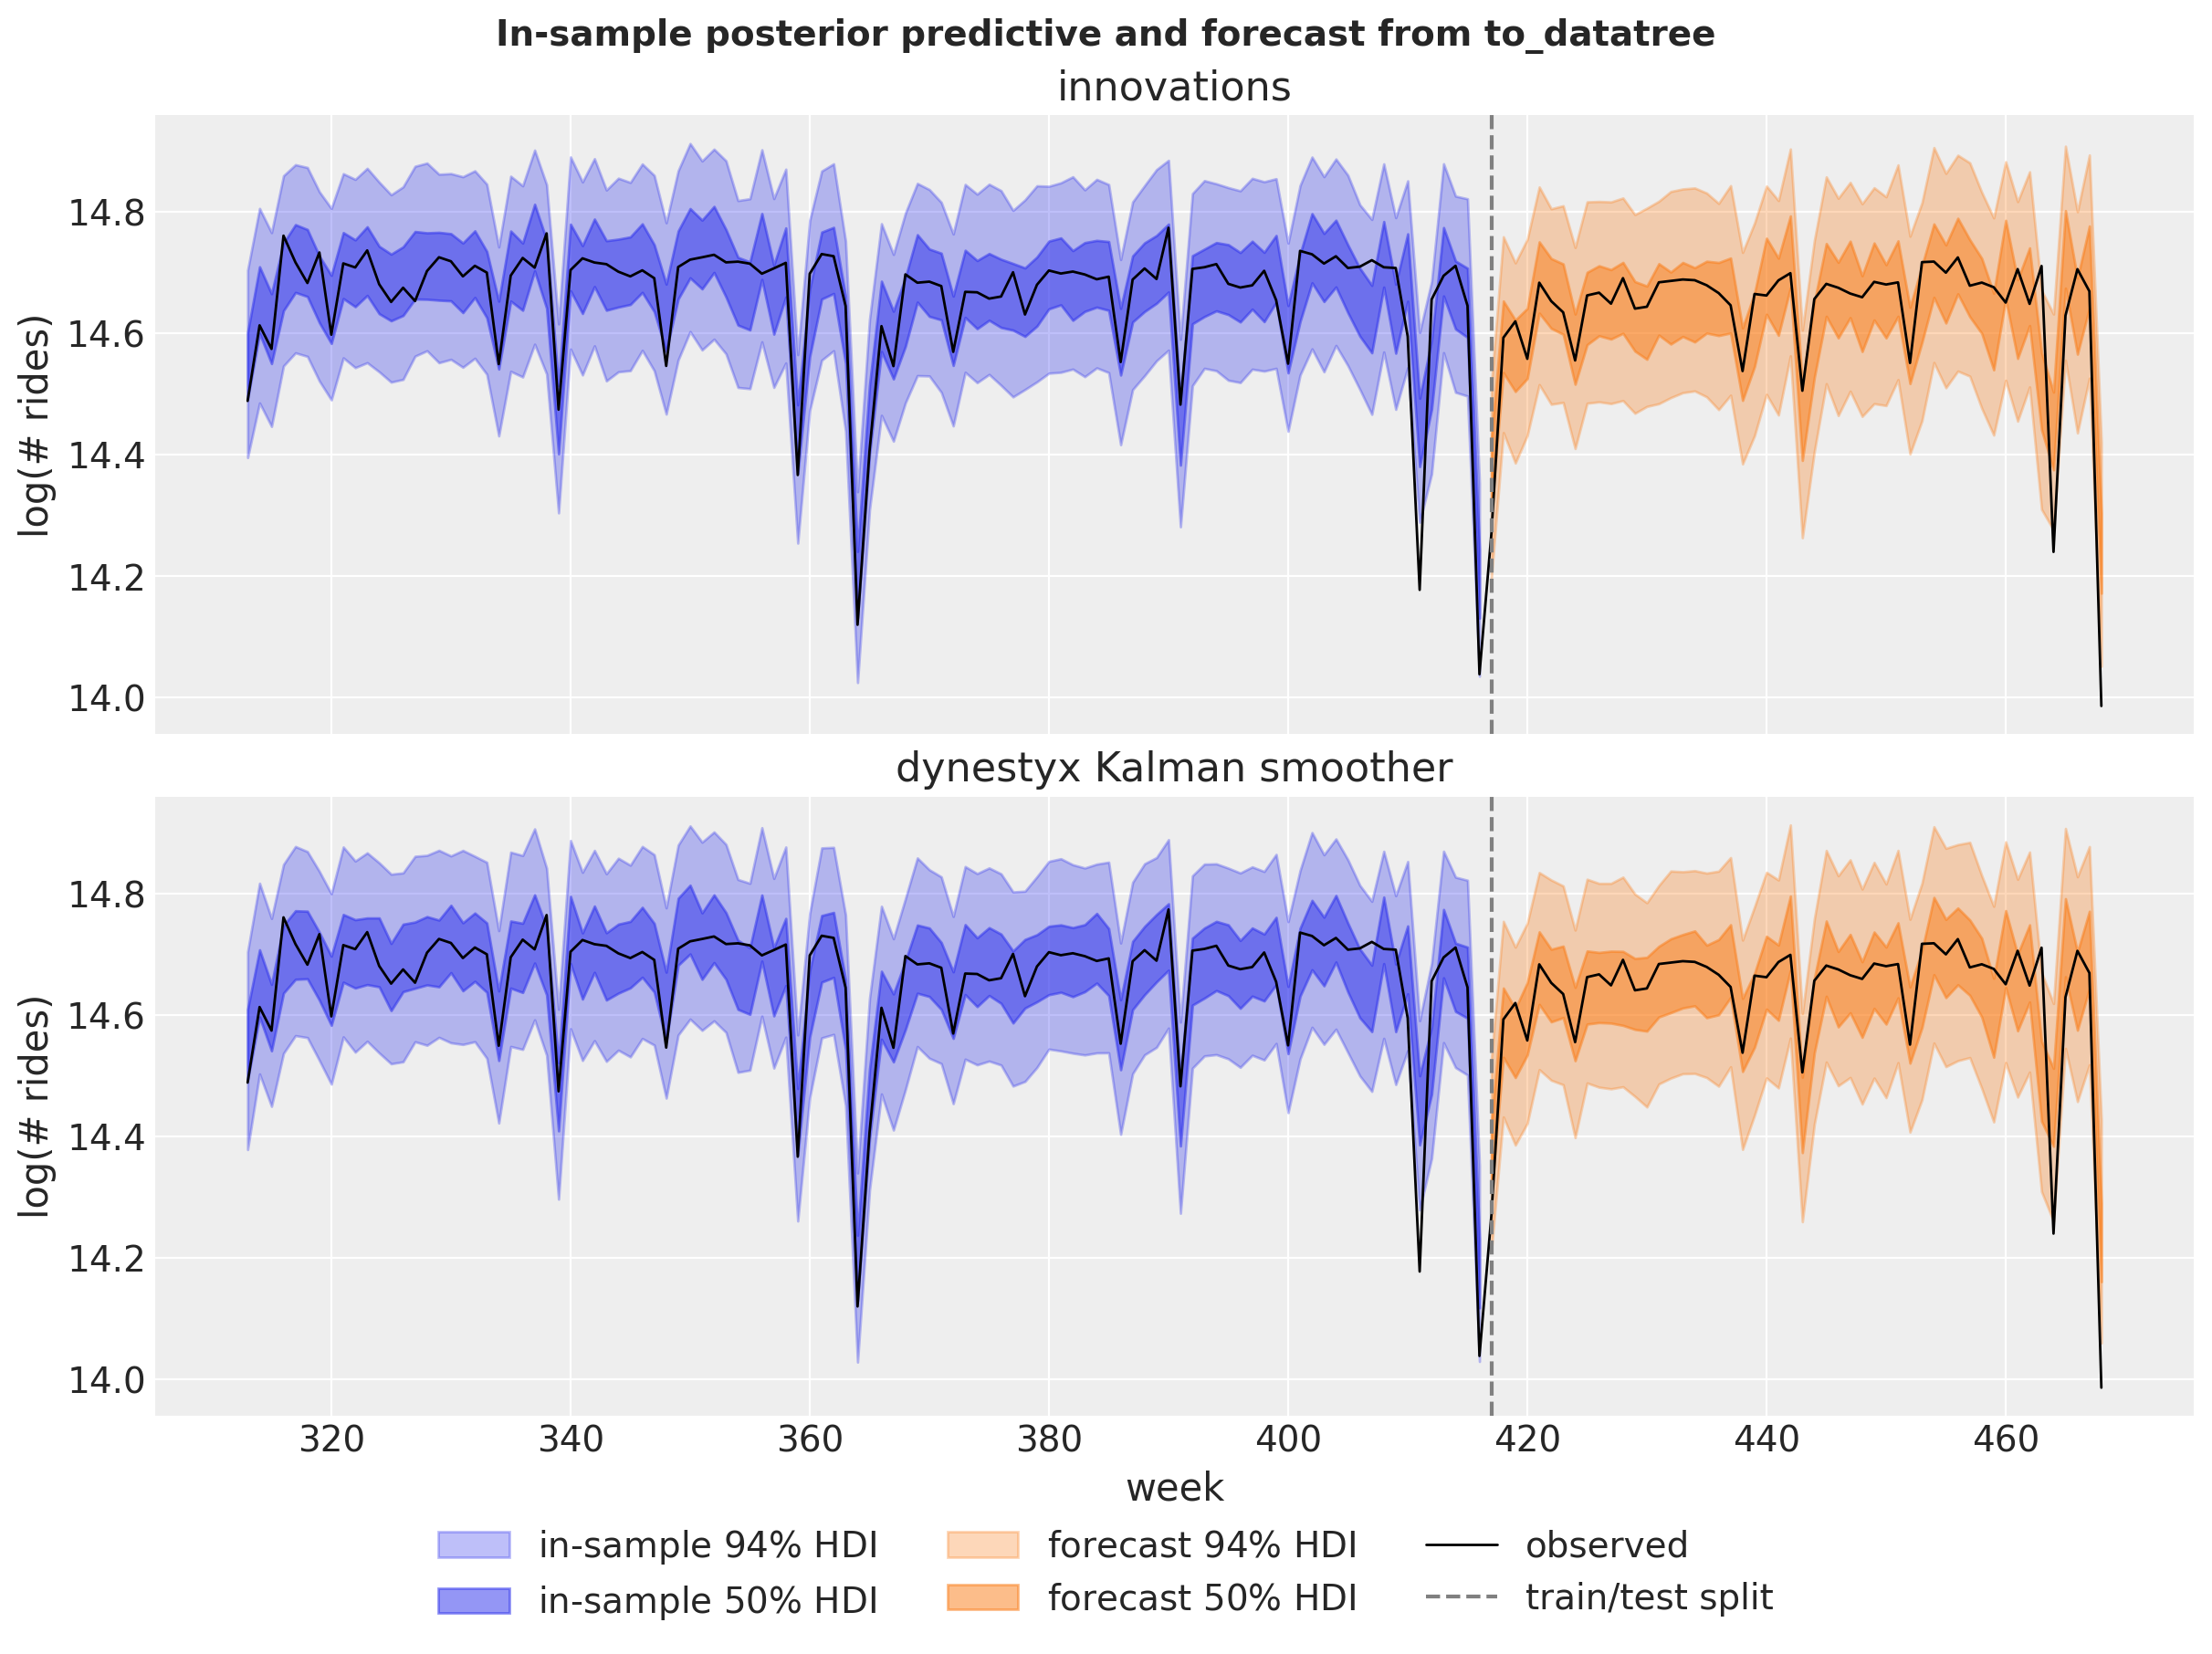

In [22]:
fig, axes = plt.subplots(
    nrows=2, ncols=1, figsize=(12, 9), sharex=True, sharey=True, layout="constrained"
)
start = t_obs - 104  # the last two years of the training window, then the test year

for ax, (label, tree) in zip(axes, trees.items(), strict=True):
    for group, color, span in (
        ("posterior_predictive", "C0", slice(start, t_obs)),
        ("predictions", "C1", slice(None)),
    ):
        draws = stacked(tree, group)
        name = "in-sample" if group == "posterior_predictive" else "forecast"
        weeks = week[start:t_obs] if group == "posterior_predictive" else week[t_obs:]
        for prob, alpha in ((0.94, 0.3), (0.5, 0.5)):
            lower, upper = hdi_bounds(draws, prob)
            ax.fill_between(
                weeks,
                lower[span],
                upper[span],
                color=color,
                alpha=alpha,
                label=hdi_label(prob, prefix=f"{name} "),
            )

    ax.plot(week[start:], bart[start:, 0], color="black", lw=1, label="observed")
    ax.axvline(t_obs, color="gray", ls="--", label="train/test split")
    ax.set(title=label, ylabel="log(# rides)")

axes[-1].set(xlabel="week")
handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=3)
fig.suptitle(
    "In-sample posterior predictive and forecast from to_datatree", fontsize=14, fontweight="bold"
);

The two models give the same bands. The in-sample band is the observation noise around the level, and the forecast band is only a little wider: the weekly steps of the level are small, so one year of them adds little to the observation noise. The `dynestyx` band comes from per-week smoothing draws and the `innovations` band from joint paths, and for every single week the two are the same distribution, which is all these bands show.

## Missing Data

The `LatentPathBuilder` skips missing observations, so the Student-T model fits through a gap with no change to the model function. (The Kalman filter and smoother of the `cuthbert` backend skip them too, while the `cd_dynamax` backend rejects them.) We remove $20$ weeks of the training window. The block reads the observed window from column $0$ of the covariates, so the gap goes there as `NaN`. A `NaN` in `data` alone would not reach the likelihood. We also put the gap into `data`, which `to_datatree` would store as the observed data.

The gap fit gets its own `LatentPathBuilder`. A builder keeps one pattern of missing observations per site name and shape, so a second fit with the same builder would replace the pattern that the drivers of the first fit read.

In [23]:
gap = slice(300, 320)
bart_gap = bart_train.at[gap].set(jnp.nan)
bart_covariates_gap = bart_covariates.at[gap, 0].set(jnp.nan)
gap_builder = LatentPathBuilder()
rng_key, key_gap = random.split(rng_key)

with gap_builder:
    mcmc_gap, _ = fit_nuts(
        key_gap,
        level_regression,
        bart_covariates_gap[:t_obs],
        bart_gap,
        num_warmup=2_000,
        chain_method="sequential",
    )

pd.DataFrame({"gap fit": convergence(mcmc_gap, bart_names)}).T.round(
    {"min bulk ESS": 0, "max R-hat": 3, "divergences": 0}
)

,min bulk ESS,max R-hat,divergences
gap fit,65.0,1.045,0.0


The gap fit mixes even more slowly than the explicit path on all weeks (smallest bulk ESS $65$ against $117$, largest $\hat{R}$ $1.045$), with no divergent transitions, so its summaries are approximate too.

We draw the in-sample predictive of the gap fit, which covers the gap weeks, under the builder of that fit. As a reference we use the in-sample predictive of the fit on all weeks. That fit has seen the weeks of the gap, so we expect it to score better there.

In [24]:
rng_key, key_gap_pred, key_full_pred = random.split(rng_key, 3)
in_sample = {}

with gap_builder:
    in_sample["fit with the gap"] = predict_in_sample(
        key_gap_pred,
        level_regression,
        mcmc_gap.get_samples(),
        bart_covariates_gap[:t_obs],
        batch_size=500,
    )

with latent_path:
    in_sample["fit on all weeks"] = predict_in_sample(
        key_full_pred,
        level_regression,
        mcmc_latent.get_samples(),
        bart_covariates[:t_obs],
        batch_size=500,
    )

before = slice(gap.start - 20, gap.start)
gap_scores = {}

for label, draws in in_sample.items():
    lower, upper = hdi_bounds(draws, 0.94)
    gap_scores[label] = {
        "CRPS on the gap weeks": float(eval_crps(draws[:, gap], bart_train[gap])),
        "94% HDI width, gap weeks": float((upper - lower)[gap].mean()),
        "94% HDI width, 20 weeks before": float((upper - lower)[before].mean()),
    }

pd.DataFrame(gap_scores).T.round(4)

,CRPS on the gap weeks,"94% HDI width, gap weeks","94% HDI width, 20 weeks before"
fit with the gap,0.0256,0.1944,0.1758
fit on all weeks,0.0229,0.1791,0.1787


Inside the gap, the $94\%$ band of the gap fit is about $11\%$ wider than in the $20$ weeks before ($0.194$ against $0.176$), while the band of the fit on all weeks keeps its width ($0.179$ in both windows). On the held-out weeks the CRPS of the gap fit is $0.0256$, against $0.0229$ for the fit that saw them.

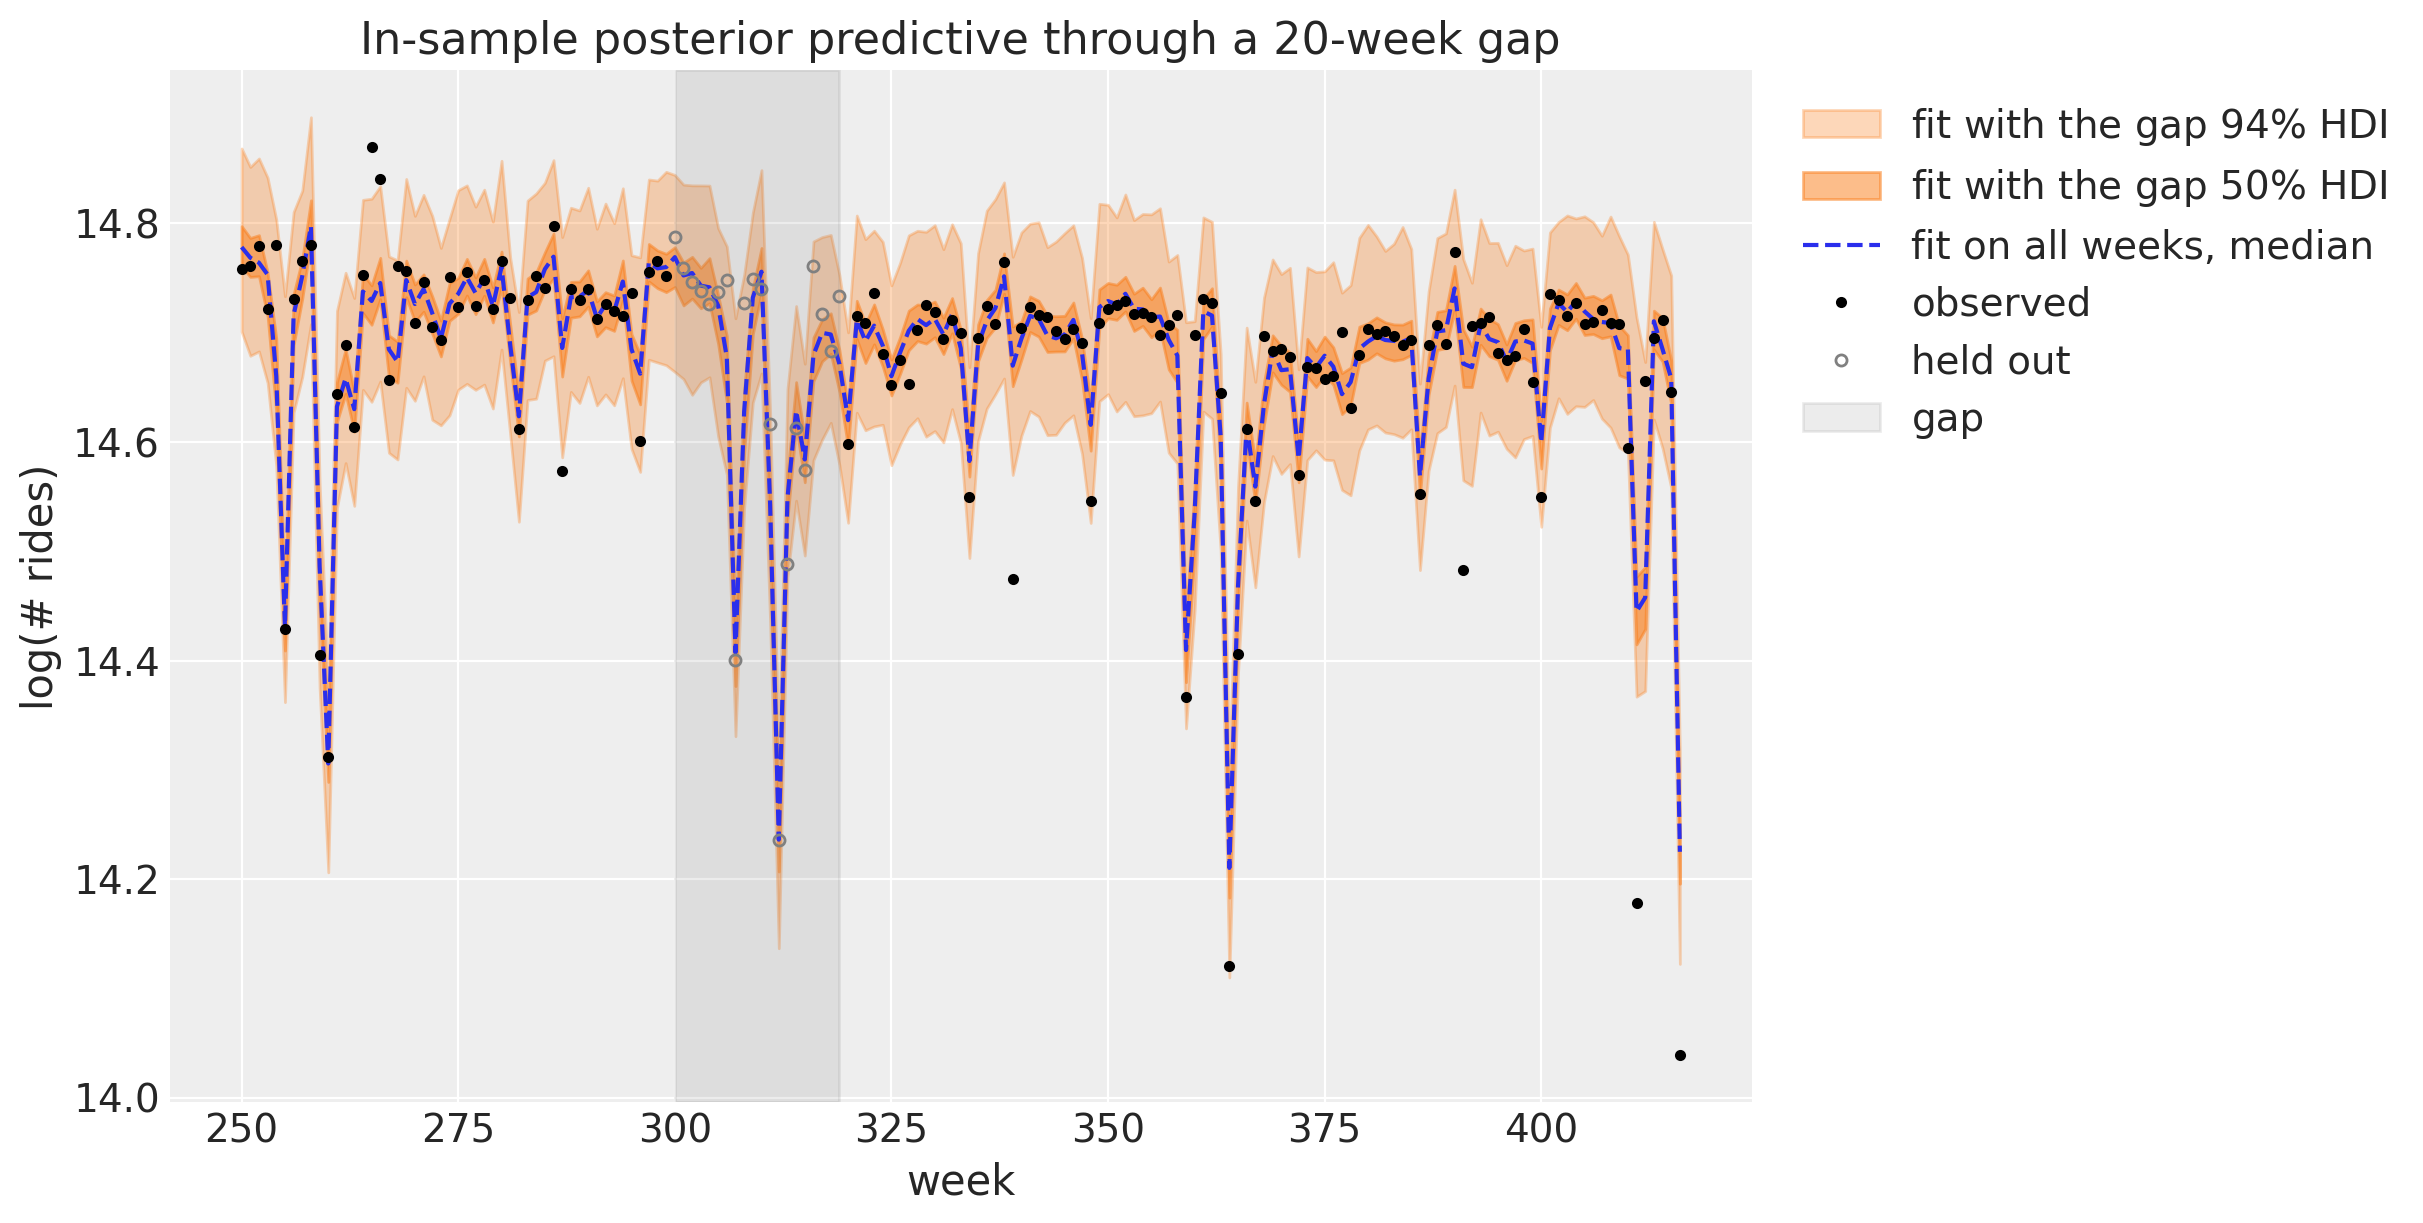

In [25]:
fig, ax = plt.subplots(figsize=(12, 6))
window = slice(250, t_obs)

for prob, alpha in ((0.94, 0.3), (0.5, 0.5)):
    lower, upper = hdi_bounds(in_sample["fit with the gap"], prob)
    ax.fill_between(
        week[window],
        lower[window],
        upper[window],
        color="C1",
        alpha=alpha,
        label=hdi_label(prob, prefix="fit with the gap "),
    )

ax.plot(
    week[window],
    np.median(np.asarray(in_sample["fit on all weeks"]), axis=0)[window, 0],
    color="C0",
    ls="--",
    label="fit on all weeks, median",
)
ax.plot(week[window], bart_gap[window, 0], "o", color="black", ms=3, label="observed")
ax.plot(week[gap], bart_train[gap, 0], "o", color="gray", ms=4, mfc="none", label="held out")
ax.axvspan(gap.start, gap.stop - 1, color="gray", alpha=0.15, label="gap")
ax.legend(loc="upper left", bbox_to_anchor=(1.01, 1.0))
ax.set(
    title="In-sample posterior predictive through a 20-week gap",
    xlabel="week",
    ylabel="log(# rides)",
);

The band follows the Fourier regression through the gap, including the two dips of the yearly cycle inside it, and the median of the fit on all weeks stays inside the band. The band widens only a little: $20$ weeks of a random walk with the small weekly steps of this series add little to the uncertainty of the level.

## Sampler Cost

The three comparisons above measure the same three quantities. The number of gradient evaluations per effective draw depends on the shape of the posterior that NUTS explores. The milliseconds per gradient depend on the model code. Their product is the compute time per effective draw, without the compilation and the overhead that the wall time includes.

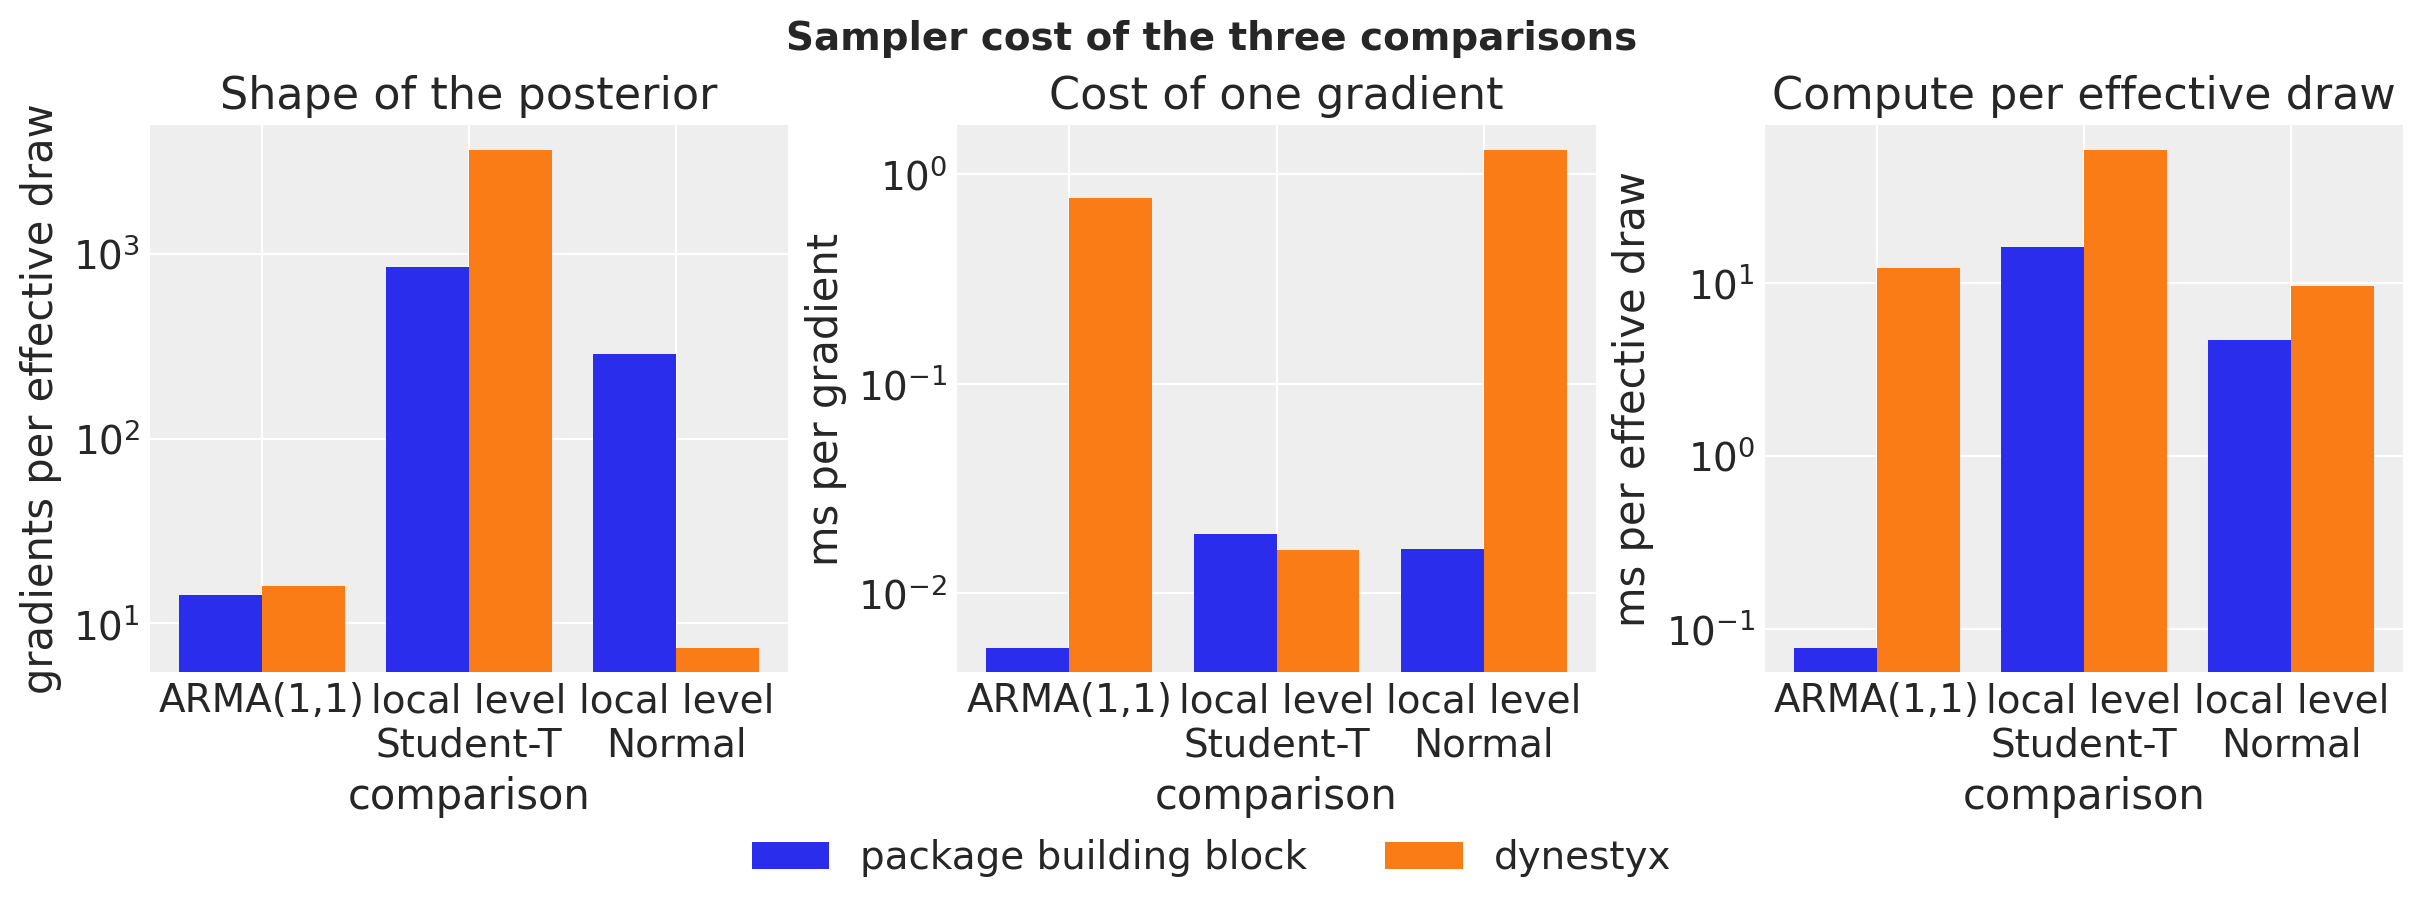

In [26]:
cost = pd.concat(
    {
        "ARMA(1,1)": pd.DataFrame(arma_cost).T,
        "local level, Student-T": pd.DataFrame(bart_cost).T,
        "local level, Normal": pd.DataFrame(gaussian_cost).T,
    },
    names=["comparison", "fit"],
)
cost["ms per effective draw"] = cost["gradients per effective draw"] * cost["ms per gradient"]

fig, axes = plt.subplots(nrows=1, ncols=3, figsize=(12, 4.5), layout="constrained")
comparisons = list(cost.index.get_level_values("comparison").unique())
positions = np.arange(len(comparisons))

panels = {
    "gradients per effective draw": "Shape of the posterior",
    "ms per gradient": "Cost of one gradient",
    "ms per effective draw": "Compute per effective draw",
}

for ax, (column, title) in zip(axes, panels.items(), strict=True):
    for offset, (library, color) in zip(
        (-0.2, 0.2), (("package building block", "C0"), ("dynestyx", "C1")), strict=True
    ):
        values = [
            cost.loc[name, column].iloc[0 if library == "package building block" else 1]
            for name in comparisons
        ]
        ax.bar(positions + offset, values, width=0.4, color=color, label=library)

    ax.set_yscale("log")
    ax.set_xticks(positions, [name.replace(", ", "\n") for name in comparisons])
    ax.set(title=title, xlabel="comparison", ylabel=column)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(handles, labels, loc="outside lower center", ncols=2)
fig.suptitle("Sampler cost of the three comparisons", fontsize=14, fontweight="bold");

In the ARMA comparison both models sample the same four parameters, so they need about the same number of gradients per effective draw, and the more expensive gradient of the Kalman filter decides: the `ssoe` model is about two orders of magnitude cheaper per effective draw. For the Student-T level, the explicit path of `dynestyx` needs about four times as many gradients per effective draw as `innovations`, because of the slow `drift_scale`, and its slightly cheaper gradients do not make up for that. For the Normal level, the Kalman filter needs about $40$ times fewer gradients per effective draw, but its gradients cost about $80$ times more, so it needs about twice the compute per effective draw. The filter makes the posterior easy for NUTS. Whether it also saves time depends on the cost of its gradient, which grows with the length of the series and the size of the state.

## Conclusion

### Key Findings

- **One model function, any handler.** `state_space` turns a `DynamicalModel` into a `numpyro_forecast` model. The handler around each call selects the inference: a Kalman filter or smoother integrates the level out, a `LatentPathBuilder` samples it. `forecast`, `predict_in_sample` and `to_datatree` work unchanged with the handler around the call.
- **Same posteriors, same forecasts.** Where both fits converge, the `dynestyx` models and the building blocks of the package give the same posteriors. The forecasts of the two BART comparisons agree, with test CRPS values within $0.0002$ of each other, and so do the in-sample bands of the two Normal models.
- **Integrating out moves the cost.** With the Kalman filter, NUTS needs few leapfrog steps per draw and few gradients per effective draw, has no divergent transitions, and each gradient costs more. For the Normal level on the CPU, the filter needs about twice the compute per effective draw of `innovations`.
- **The explicit path is general.** The `LatentPathBuilder` accepts non-Gaussian observation models and missing observations. It samples the states in centered form, and here `drift_scale` mixes slowly under it.

### Limitations

- The in-sample draws under a smoother are independent across weeks. For joint paths, use `innovations` or a `LatentPathBuilder`.
- The `LatentPathBuilder` has no reparameterization option. Every later call must use the builder instance of the fit, and parallel chains under it crashed the process on the machine that executed this notebook.
- The block models one series per model function, with the step index as its time grid.
- Without a handler around a call, `dynestyx` picks one itself and does not warn, so always pass the handler and its configuration.

### Next Steps

The [advanced `dynestyx` example](dynestyx_integration.html) compares filtering and smoothing on a local level model, measures the cost of a full evaluation against a gradient, fits a seasonal model with SVI, and backtests a `dynestyx` model with expanding windows.